# From HCD absorbers to a mock inference: a tutorial for `hcd_priya`

**PROVISIONAL (PI to refine).** This notebook has three parts.

1. **Scientific motivation.** The Lyman-alpha forest and the high-column-density (HCD) absorbers on the same
   sightlines: Lyman limit systems (LLS), sub-damped and damped Lyman-alpha absorbers (subDLAs, DLAs).
2. **The emulator.** What the published model `hcd_priya` 1.0.0 returns: the flux power spectrum (P1D) of four
   classes of sightline, the incidence of the absorbers, and a mixture of the classes.
3. **Mock inference.** A Gaussian likelihood on a mock made by the model itself, with four free parameters. It is
   a self-consistency demonstration: not an independent validation, not a result from data.

**To run it:** `pip install "hcd-priya[tutorials]"` in Python 3.11 or later, then open this file with Jupyter. The
trained model comes with the package. The few stored files the notebook reads are found in a clone of the
repository or downloaded once, each checked against its sha256 (next cell).

In [1]:
import json
import warnings

import matplotlib.pyplot as plt
import numpy as np

import hcd_analysis
import hcd_analysis.predictor as hp

plt.rcParams.update({"font.size": 12, "axes.titlesize": 12, "axes.labelsize": 12, "legend.fontsize": 10,
                     "figure.dpi": 90, "axes.grid": True, "grid.alpha": 0.3})
CLASS_COLOURS = {"clean": "#4d4d4d", "LLS": "#1f77b4", "subDLA": "#ff7f0e", "DLA": "#d62728"}

print("hcd_analysis", hcd_analysis.__version__)

hcd_analysis 1.0.0


In [2]:
# The stored files of this tutorial. Each is named by its path in the repository (a file of the GitHub release by
# its file name) and pinned by its sha256. Every URL is immutable: the tag v1.0.0, a file of the release v1.0.0,
# or one commit.
import hashlib
import os
import pathlib
import tempfile
import urllib.request

ASSETS = {
    "docs/figures/data/ho21/cddf_z225.txt": {
        "sha256": "feaffb7b88215e767ca53a41fb3f00b65c90aaf27745c28720b32976a9168a63",
        "url": "https://raw.githubusercontent.com/jibanCat/hcd_priya/v1.0.0/docs/figures/data/ho21/cddf_z225.txt",
    },
    "docs/figures/data/ho21/cddf_z253.txt": {
        "sha256": "62e93a1e1977b3d78b9f56475bd4390c1eee7eaf371986ca5ece2db338bb7cc7",
        "url": "https://raw.githubusercontent.com/jibanCat/hcd_priya/v1.0.0/docs/figures/data/ho21/cddf_z253.txt",
    },
    "docs/figures/data/ho21/cddf_z34.txt": {
        "sha256": "f21dca06cd5974a08de13632ef74109f5b78afc2921f86ec9b3c6cf9f838ad3a",
        "url": "https://raw.githubusercontent.com/jibanCat/hcd_priya/v1.0.0/docs/figures/data/ho21/cddf_z34.txt",
    },
    "docs/figures/data/ho21/dndx_all.txt": {
        "sha256": "fb4d86151b34240902dbd6e63914e7c98dbb367fb6880a0e6871c849345ca81c",
        "url": "https://raw.githubusercontent.com/jibanCat/hcd_priya/v1.0.0/docs/figures/data/ho21/dndx_all.txt",
    },
    "docs/figures/data/lls_incidence/lls_lz_literature.dat": {
        "sha256": "c7fd68c9effd2f0151fa5293ca57214a106c31e1e4611d63a6442b2b2ff47ae1",
        "url": "https://raw.githubusercontent.com/jibanCat/hcd_priya/v1.0.0/docs/figures/data/lls_incidence/lls_lz_literature.dat",
    },
    "docs/figures/data/lls_subdla/zafar_2013.txt": {
        "sha256": "f592ecfd74bb423eae15d9bf40c7aca3e3da61ee7bbc1dab9510e6edca4767bd",
        "url": "https://raw.githubusercontent.com/jibanCat/hcd_priya/v1.0.0/docs/figures/data/lls_subdla/zafar_2013.txt",
    },
    "docs/figures/data/lls_subdla/omeara2007_fn_all19p0.dat": {
        "sha256": "695fd5e611368249b17b8de0ccf42aab8ee5c74c68f0750f7997c6c3d81f70bc",
        "url": "https://raw.githubusercontent.com/jibanCat/hcd_priya/v1.0.0/docs/figures/data/lls_subdla/omeara2007_fn_all19p0.dat",
    },
    "docs/figures/data/lls_subdla/prochaska2010_lls_region.dat": {
        "sha256": "9afad095522ac3d25ea1b615df91b806758ab50b42268dd6fea37412d689b39b",
        "url": "https://raw.githubusercontent.com/jibanCat/hcd_priya/v1.0.0/docs/figures/data/lls_subdla/prochaska2010_lls_region.dat",
    },
    "docs/figures/data/class_ratio_ranges_z3p0_lf60.csv": {
        "sha256": "0f79f1e5260df432fbe3b69b32dd4d4ebca248e95f789b11c40be549ef926f05",
        "url": "https://raw.githubusercontent.com/jibanCat/hcd_priya/v1.0.0/docs/figures/data/class_ratio_ranges_z3p0_lf60.csv",
    },
    "hcd_priya_example_download.tar.gz": {
        "sha256": "27bd0f96c88ae195175351bbf05468188b8fdf745c99bac9e54bebf571e31d7a",
        "url": "https://github.com/jibanCat/hcd_priya/releases/download/v1.0.0/hcd_priya_example_download.tar.gz",
    },
    "notebooks/tutorial/assets/figures/joss_architecture.png": {
        "sha256": "47302de8ce8d49e523312e1a67590ce8f0829cfa3d728e8cb304723bd3f6c68d",
        "url": "https://raw.githubusercontent.com/jibanCat/hcd_priya/7caaeb52c9ecffd9c6472a8231533389c990cc86/notebooks/tutorial/assets/figures/joss_architecture.png",
    },
}

# Inside a clone of the repository the files are on disk already. A local file is used when, and only when, its
# sha256 is the pinned one, so the notebook reads the same bytes inside a clone and outside one. This notebook's
# folder is two levels below the top of a clone.
LOCAL_ROOTS = (pathlib.Path.cwd(), pathlib.Path.cwd().parent.parent)


def sha256_of(path):
    digest = hashlib.sha256()
    with open(path, "rb") as handle:
        for block in iter(lambda: handle.read(1 << 20), b""):
            digest.update(block)
    return digest.hexdigest()


def tutorial_cache():
    # the folder downloaded files are kept in
    return pathlib.Path(os.environ.get("HCD_PRIYA_TUTORIAL_CACHE", "~/.cache/hcd_priya_tutorial")).expanduser()


def tutorial_file(relpath):
    # The path of a stored file of the tutorial, with the pinned sha256: a local copy in a clone, a copy
    # downloaded earlier, or a new download into the cache folder (the environment variable
    # HCD_PRIYA_TUTORIAL_CACHE, default ~/.cache/hcd_priya_tutorial).
    if relpath not in ASSETS:
        raise RuntimeError(f"{relpath} is not a stored file of this tutorial (ASSETS names {len(ASSETS)} files)")
    pinned, url = ASSETS[relpath]["sha256"], ASSETS[relpath]["url"]
    for root in LOCAL_ROOTS:
        local = pathlib.Path(root) / relpath
        if local.is_file() and sha256_of(local) == pinned:
            return local
    cache = tutorial_cache()
    target = cache / relpath
    if target.is_file() and sha256_of(target) == pinned:
        return target
    target.parent.mkdir(parents=True, exist_ok=True)
    # written under a temporary name and renamed only after the digest is checked: no partial file is left
    handle, partial = tempfile.mkstemp(dir=target.parent, prefix=target.name + ".", suffix=".part")
    digest = hashlib.sha256()
    try:
        try:
            with os.fdopen(handle, "wb") as out, urllib.request.urlopen(url, timeout=120) as response:
                for block in iter(lambda: response.read(1 << 20), b""):
                    out.write(block)
                    digest.update(block)
        except Exception as exc:
            raise RuntimeError(
                f"could not download the tutorial file {relpath} from {url} into the cache folder {cache}: {exc}"
            ) from exc
        if digest.hexdigest() != pinned:
            raise RuntimeError(
                f"the tutorial file {relpath} downloaded from {url} has sha256 {digest.hexdigest()}, "
                f"not the pinned {pinned}: it is refused, and nothing is kept in {cache}"
            )
        os.replace(partial, target)
    finally:
        if os.path.exists(partial):
            os.remove(partial)
    return target


print(len(ASSETS), "stored files are pinned by sha256")

11 stored files are pinned by sha256


## Part I. Scientific motivation

**PROVISIONAL (PI to refine).**

**Fig. 1.** PLACEHOLDER: the image from the Leinweber talk (the PI supplies the file and its terms).

**PROVISIONAL (PI to refine).** The figure is to show one quasar sightline: the Lyman-alpha forest, and the
absorbers of high column density on the same sightline, a Lyman limit system (LLS), a sub-damped and a damped
Lyman-alpha absorber (subDLA, DLA) with their damping wings.

### Three classes of absorber

**PROVISIONAL (PI to refine).** The package sorts absorbers by their neutral hydrogen column density $N_\mathrm{HI}$
into three classes, LLS, subDLA and DLA. The next cell prints the edges the package uses and draws the column
density distribution $f(N_\mathrm{HI})$ of published measurements across the three classes. A sightline belongs to
the class of its strongest absorber; a sightline with no such absorber is called clean.

LLS:    10^17.2 <= N_HI < 10^19.0 cm^-2
subDLA: 10^19.0 <= N_HI < 10^20.3 cm^-2
DLA:    N_HI >= 10^20.3 cm^-2


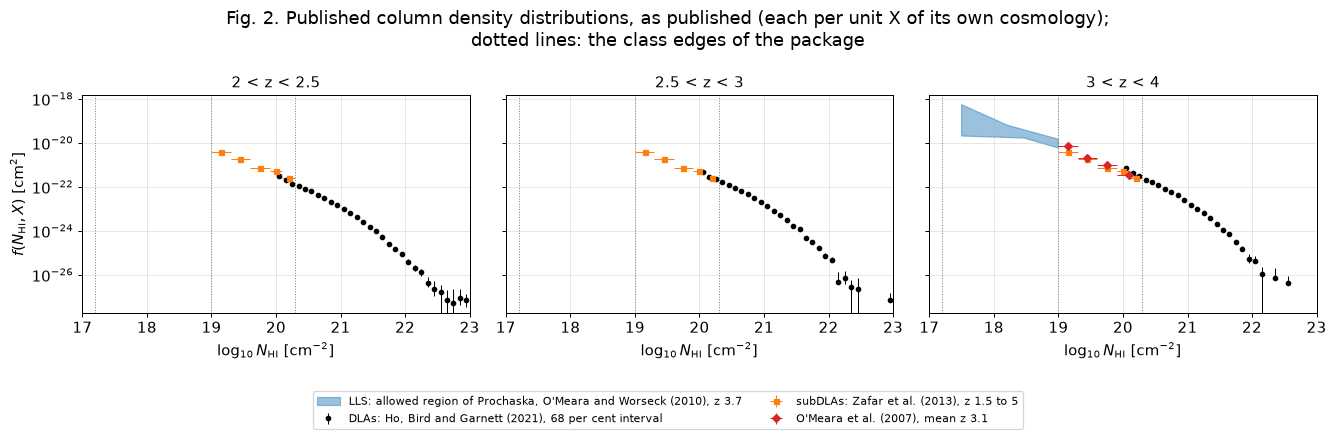

the points drawn run from log10 N_HI = 17.50 to 22.95
and f from 5.24e-19 down to 5.28e-28 cm^2: 9.0 decades of f
the forest lies below the lowest class edge, log10 N_HI = 17.2, and is not drawn


In [3]:
# Fig. 2. The column density distribution f(N_HI) from published measurements, from LLS to DLAs.
import hcd_analysis.catalog as catalog

EDGES = (catalog.LOG_NHI_LLS_MIN, catalog.LOG_NHI_SUBDLA_MIN, catalog.LOG_NHI_DLA_MIN)
print(f"LLS:    10^{EDGES[0]} <= N_HI < 10^{EDGES[1]} cm^-2")
print(f"subDLA: 10^{EDGES[1]} <= N_HI < 10^{EDGES[2]} cm^-2")
print(f"DLA:    N_HI >= 10^{EDGES[2]} cm^-2")

DATA = "docs/figures/data/"
CDDF_PANELS = (
    ("2 < z < 2.5", "ho21/cddf_z225.txt"),
    ("2.5 < z < 3", "ho21/cddf_z253.txt"),
    ("3 < z < 4", "ho21/cddf_z34.txt"),
)


def read_ho21_cddf(path):
    # six rows: log10 N_HI of the bin centre, f, the two limits of the 68 per cent interval, those of the 95 per cent
    # interval (not drawn); bins with f = 0 are left out
    table = np.loadtxt(path)
    keep = table[1] > 0
    return table[0][keep], table[1][keep], table[2][keep], table[3][keep]


# Zafar et al. (2013): log10 N_HI, the half-width of the bin, log10 f, its upper and its lower error in dex
z13_logn, z13_half, z13_logf, z13_up, z13_down = np.loadtxt(tutorial_file(DATA + "lls_subdla/zafar_2013.txt"), ndmin=2).T
# O'Meara et al. (2007), all log10: N_HI, f, the two edges of the bin, the two limits of f
o07_logn, o07_logf, o07_lo_n, o07_hi_n, o07_lo_f, o07_hi_f = np.loadtxt(
    tutorial_file(DATA + "lls_subdla/omeara2007_fn_all19p0.dat"), ndmin=2
).T
# Prochaska, O'Meara and Worseck (2010): the corners of the allowed region, log10 N_HI and log10 f
p10 = np.loadtxt(tutorial_file(DATA + "lls_subdla/prochaska2010_lls_region.dat"), ndmin=2)

fig, axes = plt.subplots(1, 3, figsize=(15, 4.8), sharey=True)
drawn_logn, drawn_f = [], []
for ax, (title, name) in zip(axes, CDDF_PANELS):
    logn, f, f_lo, f_hi = read_ho21_cddf(tutorial_file(DATA + name))
    ax.errorbar(logn, f, yerr=[f - f_lo, f_hi - f], fmt="o", ms=3.5, color="black", elinewidth=0.8,
                label="DLAs: Ho, Bird and Garnett (2021), 68 per cent interval")
    z13_f = 10.0**z13_logf
    ax.errorbar(z13_logn, z13_f, xerr=z13_half, yerr=[z13_f - 10.0 ** (z13_logf - z13_down), 10.0 ** (z13_logf + z13_up) - z13_f],
                fmt="s", ms=4, color=CLASS_COLOURS["subDLA"], elinewidth=0.8, label="subDLAs: Zafar et al. (2013), z 1.5 to 5")
    drawn_logn += [logn, z13_logn]
    drawn_f += [f, z13_f]
    if title == "3 < z < 4":
        o07_f = 10.0**o07_logf
        ax.errorbar(o07_logn, o07_f, xerr=[o07_logn - o07_lo_n, o07_hi_n - o07_logn],
                    yerr=[o07_f - 10.0**o07_lo_f, 10.0**o07_hi_f - o07_f], fmt="D", ms=4, color=CLASS_COLOURS["DLA"],
                    elinewidth=0.8, label="O'Meara et al. (2007), mean z 3.1")
        ax.fill(p10[:, 0], 10.0 ** p10[:, 1], facecolor=CLASS_COLOURS["LLS"], edgecolor=CLASS_COLOURS["LLS"], alpha=0.45, lw=1.0,
                label="LLS: allowed region of Prochaska, O'Meara and Worseck (2010), z 3.7")
        drawn_logn += [o07_logn, p10[:, 0]]
        drawn_f += [o07_f, 10.0 ** p10[:, 1]]
    for edge in EDGES:
        ax.axvline(edge, color="grey", lw=0.8, ls=":")
    ax.set_yscale("log")
    ax.set_xlim(17.0, 23.0)
    ax.set_xlabel(r"$\log_{10} N_\mathrm{HI}$ [cm$^{-2}$]")
    ax.set_title(title)
axes[0].set_ylabel(r"$f(N_\mathrm{HI}, X)$ [cm$^2$]")
fig.legend(*axes[2].get_legend_handles_labels(), loc="lower center", ncol=2, fontsize=9)
fig.suptitle("Fig. 2. Published column density distributions, as published (each per unit X of its own cosmology);\n"
             "dotted lines: the class edges of the package")
fig.tight_layout(rect=(0, 0.13, 1, 1))
plt.show()

drawn_logn, drawn_f = np.concatenate(drawn_logn), np.concatenate(drawn_f)
print(f"the points drawn run from log10 N_HI = {drawn_logn.min():.2f} to {drawn_logn.max():.2f}")
print(f"and f from {drawn_f.max():.2e} down to {drawn_f.min():.2e} cm^2: {np.log10(drawn_f.max() / drawn_f.min()):.1f} decades of f")
print(f"the forest lies below the lowest class edge, log10 N_HI = {EDGES[0]}, and is not drawn")

### Why the forest and the strong absorbers are usually treated apart

**PROVISIONAL (PI to refine).**

- *In observations.* DLAs are found one by one in the spectra and are masked, or their damping wings are fitted.
  LLS are not identified one by one at the resolution of a survey spectrum.
- *In simulations.* The strong absorbers depend on self-shielding and on resolution, and emulators of the forest
  are trained on spectra with the strong absorbers removed.

The two treatments meet in the one-dimensional flux power spectrum (P1D), which is measured on the spectra as
they are.

### What is left in the P1D

**PROVISIONAL (PI to refine). HCD contamination is not negligible for small-scale Lyman-alpha cosmology.**

PLACEHOLDER: the statements of Ho et al. (2026) and of the DESI DR1 analysis (Chaves-Montero et al. 2026) on the
absorbers that remain in a measured P1D and on the scales they affect, quoted with their references. Each
sentence is to be checked against its paper before it is written here.

References to be quoted: Ho et al., JCAP 2026 (07) 094; Chaves-Montero et al., JCAP 2026 (06) 040; the DESI DR1
measurements of the P1D, Karacayli et al. (2025) and Ravoux et al. (2025).

## Part II. The emulator

**PROVISIONAL (PI to refine).** The published model was trained on the PRIYA suite of hydrodynamical simulations.
Given nine cosmological and astrophysical parameters, a redshift and a mean flux, it returns the P1D of four
classes of sightline (clean, LLS, subDLA, DLA), the incidence of the three classes of absorber, and the column
density distribution. The next cell loads it and prints what identifies it.

In [4]:
emu = hp.load_published()  # the trained LF+MF model, from the installed package hcd-priya-models

release = emu.provenance["release"]
print("model release:", release["release_version"], "| format:", release["format"])
print("sha256 of its release.json:", release["release_sha256"])

# The point used in this notebook: the midpoint of the range each parameter was trained on. It is a point to try
# the model at: not a fiducial cosmology, not a best fit and not a simulation.
PARAMS = {
    "ns": 0.925,  # slope of the primordial power spectrum at k = 0.78 / Mpc
    "Ap": 1.9e-9,  # its amplitude at the same wavenumber
    "herei": 4.0,  # redshift at which helium reionization starts
    "heref": 2.7,  # redshift at which helium reionization ends
    "alphaq": 2.15,  # quasar spectral index, which sets the heating of helium reionization
    "hub": 0.70,  # dimensionless Hubble parameter h
    "omegamh2": 0.143,  # Omega_m h^2
    "hireionz": 7.25,  # redshift of hydrogen reionization
    "bhfeedback": 0.05,  # black-hole feedback strength
}
print()
print(f"{'parameter':11s} {'trained from':>13s} {'to':>10s} {'used here':>10s}")
for name, (low, high) in zip(hp.PARAM_NAMES, hp.PARAM_LIMITS):
    print(f"{name:11s} {low:13.4g} {high:10.4g} {PARAMS[name]:10.4g}")

# The mean flux is PRIYA's model: tau_eff(z) = tau0_amp ((1 + z) / (1 + z_pivot))**dtau0 times the fit of Kim et
# al. (2007). The model records the range of tau0_amp it was trained on with its training data:
TAU0_AMP_RANGE = tuple(emu.provenance["lineage"]["cache"]["settings"]["alpha_range"])
print(f"{'tau0_amp':11s} {TAU0_AMP_RANGE[0]:13.4g} {TAU0_AMP_RANGE[1]:10.4g} {1.0:10.4g}   (dtau0 = 0 here)")

model release: 1.0.0 | format: hcd_priya.release/1
sha256 of its release.json: c81c33ce65455098620a6e7e54e95bc87f10b06ac10970082ffbc9c6fe5470ad

parameter    trained from         to  used here
ns                    0.8       1.05      0.925
Ap                1.2e-09    2.6e-09    1.9e-09
herei                 3.5        4.5          4
heref                 2.2        3.2        2.7
alphaq                1.3          3       2.15
hub                  0.65       0.75        0.7
omegamh2             0.14      0.146      0.143
hireionz              6.5          8       7.25
bhfeedback           0.03       0.07       0.05
tau0_amp           0.6556      1.331          1   (dtau0 = 0 here)


In [5]:
import numpy as np


def cumulative_incidence(cddf, log_nhi, threshold=17.5):
    # dN/dX of every absorber with N_HI >= 10^threshold, from a column density distribution f(N_HI) at the bin
    # centres log_nhi: the sum of f times the width in N_HI of each bin's part above the threshold. The bin that
    # holds the threshold counts from it to its upper edge, with f taken constant within the bin; a bin without a
    # value (NaN) is left out. On the last axis.
    cddf = np.asarray(cddf, dtype=float)
    log_nhi = np.asarray(log_nhi, dtype=float)
    step = np.diff(log_nhi)
    if not np.allclose(step, step[0], rtol=0.0, atol=1e-9):
        raise ValueError("the bin centres of the CDDF are not evenly spaced")
    low = np.maximum(log_nhi - step[0] / 2.0, threshold)
    high = log_nhi + step[0] / 2.0
    widths = np.where(high > low, 10.0**high - 10.0**low, 0.0)
    counted = (widths > 0) & np.isfinite(cddf)
    total = np.where(counted, cddf * widths, 0.0).sum(axis=-1)
    return np.where(counted.any(axis=-1), total, np.nan)


def absorption_distance(z1, z2, omega_m):
    # Delta X from z1 to z2 in a flat cosmology with matter density omega_m:
    # the integral of (1 + z)^2 / sqrt(omega_m (1 + z)^3 + 1 - omega_m) dz (trapezoid rule on 2001 points)
    z = np.linspace(z1, z2, 2001)
    y = (1.0 + z) ** 2 / np.sqrt(omega_m * (1.0 + z) ** 3 + 1.0 - omega_m)
    return float(np.sum(0.5 * (y[1:] + y[:-1]) * np.diff(z)))

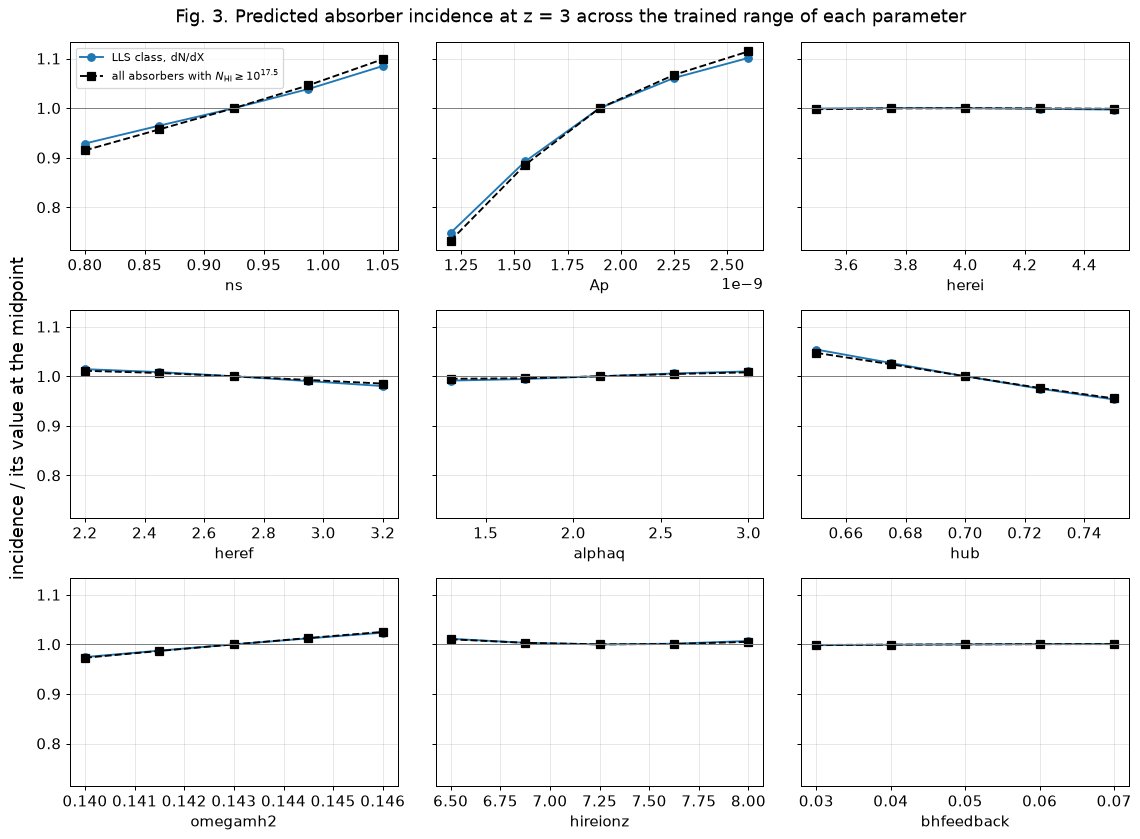

at the midpoint: dN/dX of the LLS class = 0.4337, of all absorbers above 10^17.5 = 0.5106
The change of the predicted LLS incidence across the trained range of each parameter, largest first
(the largest of the five values over the smallest; the value at the low and at the high end over the midpoint):
  Ap          x 1.471   low end 0.749, high end 1.101
  ns          x 1.168   low end 0.929, high end 1.085   flags set along the way: ns_ridge
  hub         x 1.106   low end 1.054, high end 0.953
  omegamh2    x 1.051   low end 0.974, high end 1.024
  heref       x 1.035   low end 1.014, high end 0.980   flags set along the way: outside_sampling_box
  alphaq      x 1.019   low end 0.991, high end 1.010   flags set along the way: outside_sampling_box
  hireionz    x 1.011   low end 1.011, high end 1.007
  herei       x 1.003   low end 0.999, high end 0.997   flags set along the way: outside_sampling_box
  bhfeedback  x 1.002   low end 0.998, high end 1.001


In [6]:
# Fig. 3. The predicted incidence of LLS, and of all absorbers above 10^17.5 cm^-2, at z = 3 while one parameter at
# a time crosses the range it was trained on (five values; the other eight at the midpoint, the mean flux fixed).
Z0 = 3.0
I_LLS = hp.HCD_CLASSES.index("LLS")
mid = emu.predict(PARAMS, z=Z0, tau0_amp=1.0, dtau0=0.0)
mid_flags = {name for name, value in mid.flags.items() if value is True}

response, new_flags = {}, {}
for name, (low, high) in zip(hp.PARAM_NAMES, hp.PARAM_LIMITS):
    values = np.linspace(low, high, 5)
    rows = [emu.predict(dict(PARAMS, **{name: value}), z=Z0, tau0_amp=1.0, dtau0=0.0) for value in values]
    lls = np.array([row.dndx[I_LLS] for row in rows]) / mid.dndx[I_LLS]
    above = np.array([cumulative_incidence(row.cddf, row.log_nhi) for row in rows]) / cumulative_incidence(mid.cddf, mid.log_nhi)
    response[name] = (values, lls, above)
    new_flags[name] = sorted({f for row in rows for f, value in row.flags.items() if value is True} - mid_flags)

fig, axes = plt.subplots(3, 3, figsize=(13, 9.5), sharey=True)
for ax, (name, (values, lls, above)) in zip(axes.ravel(), response.items()):
    ax.plot(values, lls, "o-", color=CLASS_COLOURS["LLS"], label="LLS class, dN/dX")
    ax.plot(values, above, "s--", color="black", label=r"all absorbers with $N_\mathrm{HI} \geq 10^{17.5}$")
    ax.axhline(1.0, color="grey", lw=0.8)
    ax.set_xlabel(name)
fig.supylabel("incidence / its value at the midpoint")
axes[0, 0].legend(fontsize=9)
fig.suptitle("Fig. 3. Predicted absorber incidence at z = 3 across the trained range of each parameter")
fig.tight_layout()
plt.show()

print(f"at the midpoint: dN/dX of the LLS class = {mid.dndx[I_LLS]:.4f}, "
      f"of all absorbers above 10^17.5 = {float(cumulative_incidence(mid.cddf, mid.log_nhi)):.4f}")
print("The change of the predicted LLS incidence across the trained range of each parameter, largest first")
print("(the largest of the five values over the smallest; the value at the low and at the high end over the midpoint):")
RANKING = sorted(response, key=lambda name: -(response[name][1].max() / response[name][1].min()))
for name in RANKING:
    values, lls, above = response[name]
    note = f"   flags set along the way: {', '.join(new_flags[name])}" if new_flags[name] else ""
    print(f"  {name:11s} x {lls.max() / lls.min():.3f}   low end {lls[0]:.3f}, high end {lls[-1]:.3f}{note}")

**PROVISIONAL (PI to refine).** Reading Fig. 3: the printed list ranks the nine parameters by how much the
predicted LLS incidence changes across the range each was trained on. The absorber population is itself a
prediction of the model, and it depends on cosmological and on astrophysical parameters; which of the two kinds
matters more is to be read from the list above and written here.

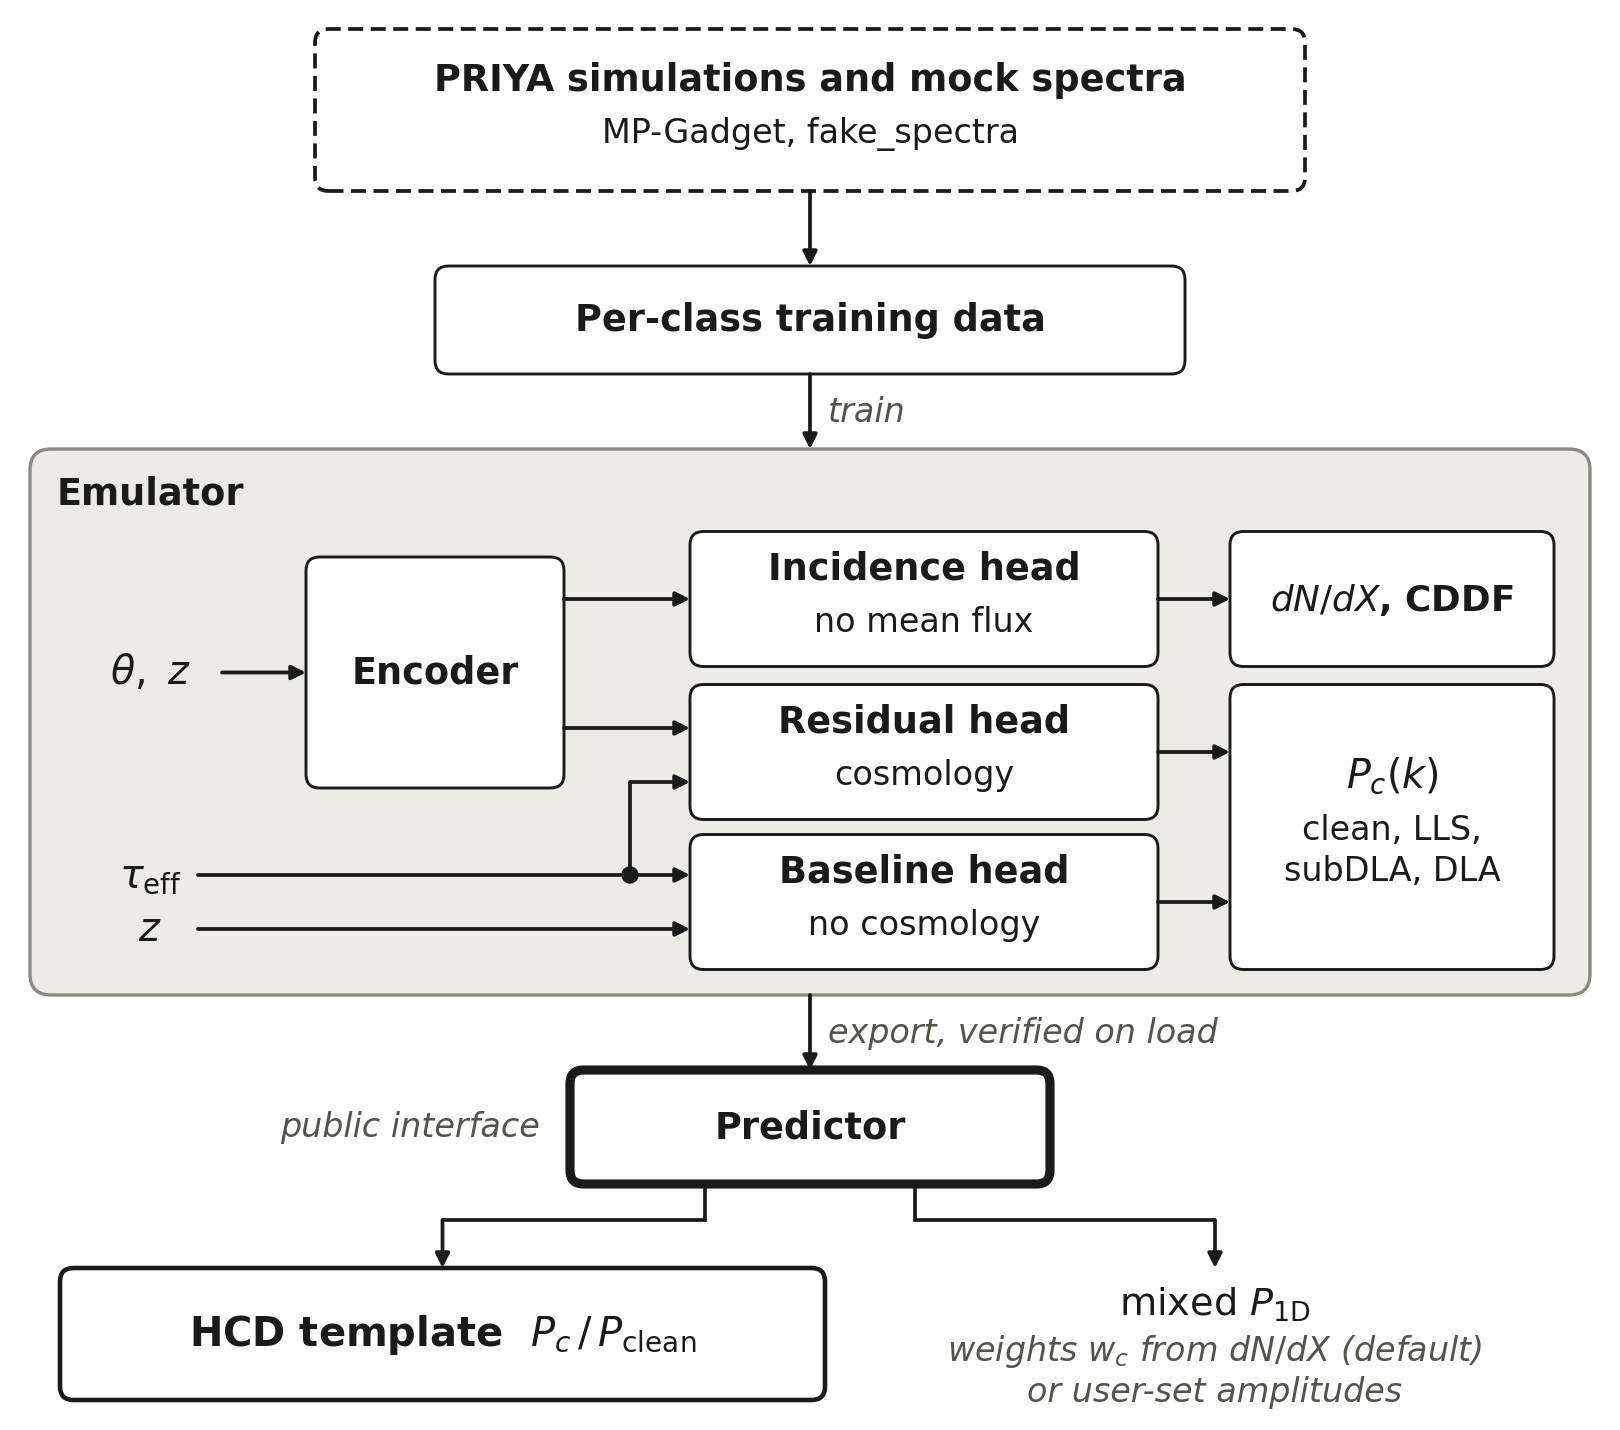

In [7]:
# Fig. 4. How the emulator is built (the schematic of the manuscript; assets/figures/PROVENANCE.md in the repository).
from IPython.display import Image, display

display(Image(filename=str(tutorial_file("notebooks/tutorial/assets/figures/joss_architecture.png")), width=900))

**Fig. 4. PROVISIONAL (PI to refine).** One model takes the nine parameters, the redshift and the mean flux, and
returns the four class spectra, with a multi-fidelity correction towards the high-resolution simulations, and the
incidence of the absorbers (dN/dX and the column density distribution).

In [8]:
pred = emu.predict(PARAMS, z=3.0, tau0_amp=1.0, dtau0=0.0)

print("model:", pred.labels["product"])
print("classes, in the order of P_class:", hp.CLASSES)
print(f"pred.k:       shape {pred.k.shape}, from {pred.k[0]:.2e} to {pred.k[-1]:.2e} s/km")
print(f"pred.P_class: shape {pred.P_class.shape}, in km/s")
print(f"pred.w_c:     the model's sightline fractions of {hp.HCD_CLASSES}: {np.round(pred.w_c, 4)}")
print(f"pred.dndx:    the incidence dN/dX of the same three classes: {np.round(pred.dndx, 4)}")
print(f"mean flux:    tau_eff = {float(pred.tau_eff):.4f}")
print("flags that are set:", sorted(name for name, value in pred.flags.items() if value is True))

model: LF+MF
classes, in the order of P_class: ('clean', 'LLS', 'subDLA', 'DLA')
pred.k:       shape (172,), from 4.76e-04 to 8.18e-02 s/km
pred.P_class: shape (4, 172), in km/s
pred.w_c:     the model's sightline fractions of ('LLS', 'subDLA', 'DLA'): [0.2126 0.0786 0.0376]
pred.dndx:    the incidence dN/dX of the same three classes: [0.4337 0.1343 0.0602]
mean flux:    tau_eff = 0.3624
flags that are set: ['incidence_heldout_error_available', 'incidence_mf_applied', 'k_downweighted', 'mf_applied', 'p1d_validation_available']


### Conventions

**PROVISIONAL (PI to refine).**

- The spectrum is that of $\delta_F = F / \langle F \rangle - 1$, with one mean flux $\langle F \rangle$ for the
  whole sample of sightlines, all classes together.
- $k$ is the angular wavenumber, in s/km.
- The class spectra are *PRIYA-filtered*: the cores of the strongest absorbers are masked in the simulated
  spectra, as for the PRIYA forest emulator, and the mixture below does not add back what the filter removed
  (`pred.labels["omissions"]` names it, and a later cell prints it).

A class spectrum is therefore a conditional spectrum under one normalisation. It is not the spectrum of isolated
absorbers. The definitions are in `docs/p1d_definition.md` of the repository.

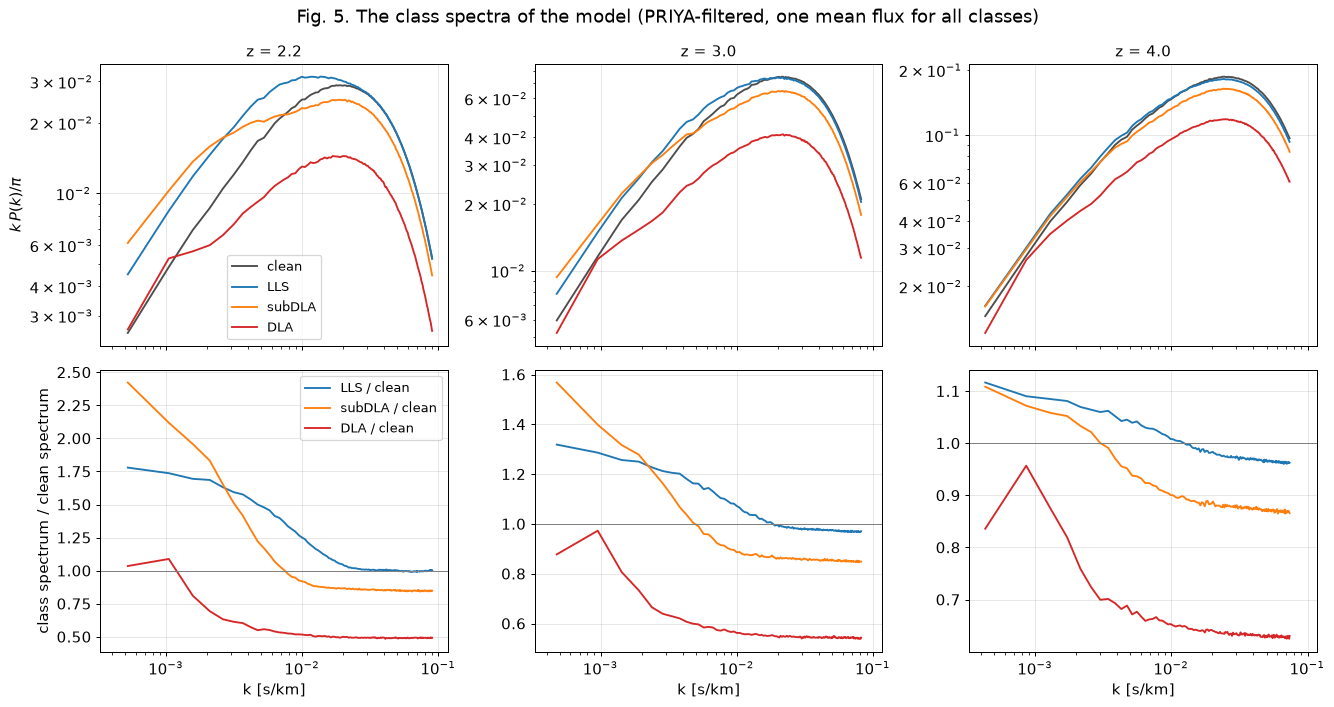

Where each class ratio lies above and below one (ranges of k in s/km):
  z = 2.2  LLS     smallest 0.990, largest 1.779; above one on 106 of 172 modes: 5.23e-04 to 4.71e-02; 4.81e-02 to 4.97e-02; 5.07e-02 to 5.07e-02; and 3 more ranges; below one: 4.76e-02 to 4.76e-02; 5.02e-02 to 5.02e-02; 5.12e-02 to 8.00e-02; and 2 more ranges
  z = 2.2  subDLA  smallest 0.842, largest 2.423; above one on 14 of 172 modes: 5.23e-04 to 7.32e-03; below one: 7.84e-03 to 8.99e-02
  z = 2.2  DLA     smallest 0.485, largest 1.089; above one on 2 of 172 modes: 5.23e-04 to 1.05e-03; below one: 1.57e-03 to 8.99e-02
  z = 3.0  LLS     smallest 0.967, largest 1.319; above one on 38 of 172 modes: 4.76e-04 to 1.81e-02; below one: 1.86e-02 to 8.18e-02
  z = 3.0  subDLA  smallest 0.847, largest 1.568; above one on 10 of 172 modes: 4.76e-04 to 4.76e-03; below one: 5.23e-03 to 8.18e-02
  z = 3.0  DLA     smallest 0.539, largest 0.973; above one on 0 of 172 modes: nowhere; below one: 4.76e-04 to 8.18e-02
  z = 4.0  LL

In [9]:
# Fig. 5. The four class spectra, and the ratio of each HCD class to the clean forest, at three redshifts.
Z_SHOWN = (2.2, 3.0, 4.0)
stack = emu.predict_many(PARAMS, z=list(Z_SHOWN), tau0_amp=1.0, dtau0=0.0)

fig, axes = plt.subplots(2, 3, figsize=(15, 8), sharex=True)
for j, z in enumerate(Z_SHOWN):
    k = stack.k[j]
    for i, name in enumerate(hp.CLASSES):
        axes[0, j].loglog(k, k * stack.P_class[j, i] / np.pi, color=CLASS_COLOURS[name], label=name)
    for i, name in enumerate(hp.CLASSES[1:], start=1):
        axes[1, j].semilogx(k, stack.P_class[j, i] / stack.P_class[j, 0], color=CLASS_COLOURS[name], label=f"{name} / clean")
    axes[1, j].axhline(1.0, color="grey", lw=0.8)
    axes[0, j].set_title(f"z = {z}")
    axes[1, j].set_xlabel("k [s/km]")
axes[0, 0].set_ylabel(r"$k\,P(k)/\pi$")
axes[1, 0].set_ylabel("class spectrum / clean spectrum")
axes[0, 0].legend()
axes[1, 0].legend()
fig.suptitle("Fig. 5. The class spectra of the model (PRIYA-filtered, one mean flux for all classes)")
fig.tight_layout()
plt.show()

def k_ranges(k, mask):
    # the contiguous ranges of k on which mask holds, as text (the first three, then how many more)
    ranges, start = [], None
    for i, flag in enumerate(mask):
        if flag and start is None:
            start = i
        if start is not None and (not flag or i == len(mask) - 1):
            ranges.append(f"{k[start]:.2e} to {k[i if flag else i - 1]:.2e}")
            start = None
    if not ranges:
        return "nowhere"
    return "; ".join(ranges[:3]) + (f"; and {len(ranges) - 3} more ranges" if len(ranges) > 3 else "")


print("Where each class ratio lies above and below one (ranges of k in s/km):")
for j, z in enumerate(Z_SHOWN):
    k = stack.k[j]
    for i, name in enumerate(hp.CLASSES[1:], start=1):
        ratio = stack.P_class[j, i] / stack.P_class[j, 0]
        above = ratio > 1.0
        print(f"  z = {z}  {name:7s} smallest {ratio.min():.3f}, largest {ratio.max():.3f}; above one on {int(above.sum())} of {k.size} modes: "
              f"{k_ranges(k, above)}; below one: {k_ranges(k, ~above)}")

**PROVISIONAL (PI to refine).** Reading Fig. 5: the printed lines say where each class has more and where it has
less power than the clean forest, as the model gives it. With the conventions above, a ratio below one is not a
defect: the classes share one mean flux, and the filter removes the core of the strongest absorbers. The physical
reading of each class is to be written here from the printed numbers.

### The mixture of the classes

**PROVISIONAL (PI to refine).** `hp.add_hcd(pred, A)` mixes the class spectra linearly:

$$P_\mathrm{mix}(k) = P_\mathrm{clean}(k) + \sum_c A_c\,[P_c(k) - P_\mathrm{clean}(k)], \qquad c \in \{\mathrm{LLS}, \mathrm{subDLA}, \mathrm{DLA}\}.$$

The amplitudes $A_c$ are fractions of sightlines. The model's own fractions at a point are `pred.w_c`.

What the mixture is not: it is not the P1D of an observed sample (the cores removed by the filter are left out,
see `pred.labels["omissions"]`); nothing is fitted; and it carries no law in redshift of its own.

the model's own fractions at this point: LLS 0.2126, subDLA 0.0786, DLA 0.0376
what the mixture leaves out:
  - the subDLA filtered remnant: the power of subDLA cores the PRIYA filter removes is not added back
  - the DLA damping-wing core: the DLA class is the PRIYA-filtered spectrum, without its core
LLS     amplitude from 0 to 2 times the model's own: the mixture changes by at most 13.03 per cent, at k = 4.76e-04 s/km, and by 1.28 per cent at the largest k
subDLA  amplitude from 0 to 2 times the model's own: the mixture changes by at most 8.40 per cent, at k = 4.76e-04 s/km, and by 2.44 per cent at the largest k
DLA     amplitude from 0 to 2 times the model's own: the mixture changes by at most 3.54 per cent, at k = 7.94e-02 s/km, and by 3.50 per cent at the largest k


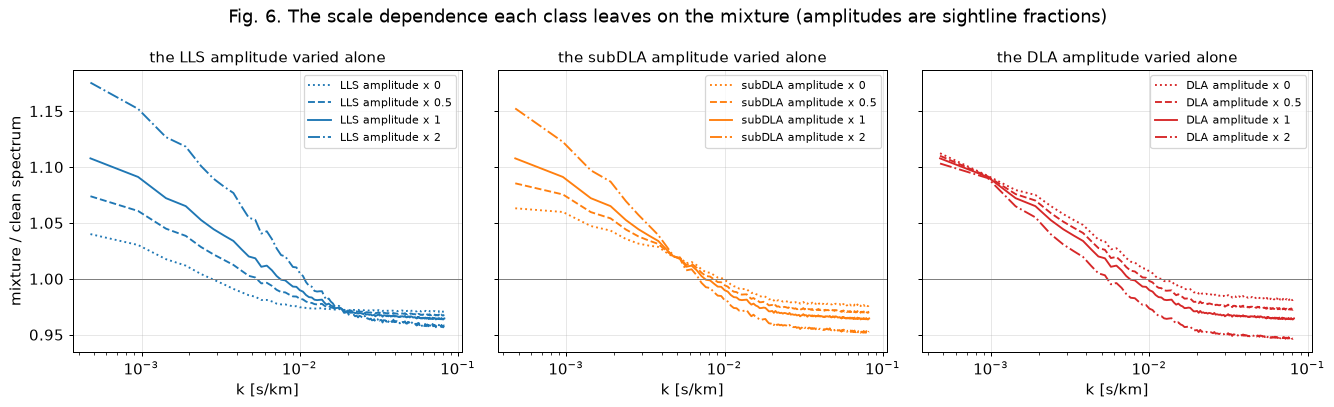

In [10]:
# Fig. 6. The mixture over the clean spectrum at z = 3, with the amplitude of one class at a time at 0, 0.5, 1 and
# 2 times the model's own fraction (the other two classes at the model's own).
FACTORS = (0.0, 0.5, 1.0, 2.0)
clean = pred.P_class[0]
print("the model's own fractions at this point:", ", ".join(f"{name} {value:.4f}" for name, value in zip(hp.HCD_CLASSES, pred.w_c)))
print("what the mixture leaves out:")
for omission in pred.labels["omissions"]:
    print("  -", omission)

fig, axes = plt.subplots(1, 3, figsize=(15, 4.6), sharey=True)
for c, name in enumerate(hp.HCD_CLASSES):
    spread = []
    for factor, style in zip(FACTORS, (":", "--", "-", "-.")):
        scale = np.ones(3)
        scale[c] = factor
        mixed = hp.add_hcd(pred, pred.w_c * scale)
        spread.append(mixed / clean)
        axes[c].semilogx(pred.k, mixed / clean, style, color=CLASS_COLOURS[name], label=f"{name} amplitude x {factor:g}")
    axes[c].axhline(1.0, color="grey", lw=0.8)
    axes[c].set_xlabel("k [s/km]")
    axes[c].set_title(f"the {name} amplitude varied alone")
    axes[c].legend(fontsize=9)
    change = np.abs(spread[-1] / spread[0] - 1.0)
    print(f"{name:7s} amplitude from 0 to 2 times the model's own: the mixture changes by at most "
          f"{100 * change.max():.2f} per cent, at k = {pred.k[change.argmax()]:.2e} s/km, "
          f"and by {100 * change[-1]:.2f} per cent at the largest k")
axes[0].set_ylabel("mixture / clean spectrum")
fig.suptitle("Fig. 6. The scale dependence each class leaves on the mixture (amplitudes are sightline fractions)")
fig.tight_layout()
plt.show()

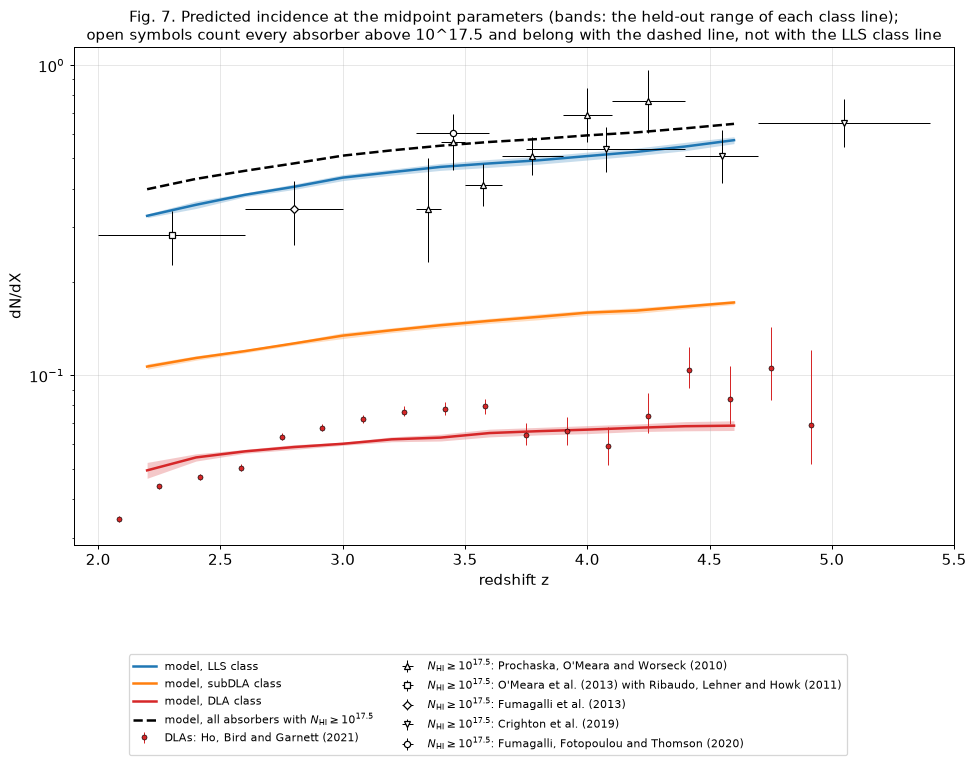

At z = 3, the model's dN/dX with its held-out range (value x exp(-e) to value x exp(+e)):
  LLS     0.4337   range 0.4242 to 0.4435
  subDLA  0.1343   range 0.1314 to 0.1372
  DLA     0.0602   range 0.0595 to 0.0609
  all absorbers above 10^17.5: 0.5106
factors applied to the measurements: Ho, Bird and Garnett (2021) 1.0202 to 1.0224 (their Omega_m 0.279 to the line's 0.2918)


In [11]:
# Fig. 7. The incidence dN/dX the model predicts, against redshift, with published measurements.
Z_VALIDATED = [z for z in hp.Z_GRID if 2.2 - 1e-9 <= z <= 4.6 + 1e-9]
inc = emu.predict_many(PARAMS, z=Z_VALIDATED, tau0_amp=1.0, dtau0=0.0)
inc_above = cumulative_incidence(inc.cddf, inc.log_nhi)
OMEGA_M = PARAMS["omegamh2"] / PARAMS["hub"] ** 2  # the flat cosmology of the model line

# DLAs, Ho, Bird and Garnett (2021): the bin centre in z, dN/dX, the two limits of the 68 per cent interval (and of
# the 95 per cent interval, not drawn), per unit X of their flat cosmology with Omega_m = 0.279. A measurement per
# unit X is drawn in the cosmology of the model line: times Delta X(its own) / Delta X(the line's) over its bin.
ho21 = np.loadtxt(tutorial_file(DATA + "ho21/dndx_all.txt"))
half_bin = (ho21[0][1] - ho21[0][0]) / 2.0
ho21_factor = np.array([
    absorption_distance(z - half_bin, z + half_bin, 0.279) / absorption_distance(z - half_bin, z + half_bin, OMEGA_M)
    for z in ho21[0]
])

# Absorbers with tau_912 >= 2 (N_HI >= 10^17.5, counted cumulatively), published as l(z) = dN/dz. The samples drawn
# are those of the repository's figure docs/figures/dndx_vs_ho21.png: (label, marker, whether the printed plus
# error is the smaller one and the two are swapped, as that figure does).
LLS_DRAWN = {
    "prochaska10_t4": ("Prochaska, O'Meara and Worseck (2010)", "^", True),
    "omeara13_t5_comb": ("O'Meara et al. (2013) with Ribaudo, Lehner and Howk (2011)", "s", False),
    "fumagalli13_nc": ("Fumagalli et al. (2013)", "D", False),
    "crighton19_corr": ("Crighton et al. (2019)", "v", False),
    "fumagalli20_dr16": ("Fumagalli, Fotopoulou and Thomson (2020)", "o", False),
}
lls_points = {source: [] for source in LLS_DRAWN}
with open(tutorial_file(DATA + "lls_incidence/lls_lz_literature.dat"), encoding="utf-8") as handle:
    for line in handle:
        if line.startswith("#") or not line.strip():
            continue
        z_lo, z_hi, value, err_lo, err_hi, quantity, _, source = line.rstrip("\n").split("\t")
        if source not in LLS_DRAWN:
            continue
        if quantity != "lz":
            raise ValueError(f"a row of {source} is not an l(z)")
        z_lo, z_hi, value, below, above = (float(v) for v in (z_lo, z_hi, value, err_lo, err_hi))
        if LLS_DRAWN[source][2]:
            below, above = above, below
        to_x = (z_hi - z_lo) / absorption_distance(z_lo, z_hi, OMEGA_M)  # l(X) = l(z) Delta z / Delta X
        lls_points[source].append((0.5 * (z_lo + z_hi), 0.5 * (z_hi - z_lo), to_x * value, to_x * below, to_x * above))

fig, ax = plt.subplots(figsize=(11, 8.5))
for c, name in enumerate(hp.HCD_CLASSES):
    ax.plot(Z_VALIDATED, inc.dndx[:, c], color=CLASS_COLOURS[name], lw=2, label=f"model, {name} class")
    ax.fill_between(Z_VALIDATED, inc.dndx_lower[:, c], inc.dndx_upper[:, c], color=CLASS_COLOURS[name], alpha=0.25, lw=0)
ax.plot(Z_VALIDATED, inc_above, color="black", lw=2, ls="--", label=r"model, all absorbers with $N_\mathrm{HI} \geq 10^{17.5}$")
ax.errorbar(ho21[0], ho21_factor * ho21[1], yerr=[ho21_factor * (ho21[1] - ho21[2]), ho21_factor * (ho21[3] - ho21[1])],
            fmt="o", ms=4, color=CLASS_COLOURS["DLA"], mec="black", mew=0.5, elinewidth=0.8,
            label="DLAs: Ho, Bird and Garnett (2021)")
for source, (label, marker, _) in LLS_DRAWN.items():
    zc, zh, value, below, above = np.array(lls_points[source]).T
    ax.errorbar(zc, value, xerr=zh, yerr=[below, above], fmt=marker, ms=5, color="black", mfc="white", elinewidth=0.8,
                label=r"$N_\mathrm{HI} \geq 10^{17.5}$: " + label)
ax.set_yscale("log")
ax.set_xlim(1.9, 5.5)
ax.set_xlabel("redshift z")
ax.set_ylabel("dN/dX")
fig.legend(*ax.get_legend_handles_labels(), fontsize=9, ncol=2, loc="lower center")
ax.set_title("Fig. 7. Predicted incidence at the midpoint parameters (bands: the held-out range of each class line);\n"
             "open symbols count every absorber above 10^17.5 and belong with the dashed line, not with the LLS class line")
fig.tight_layout(rect=(0, 0.2, 1, 1))
plt.show()

j3 = Z_VALIDATED.index(3.0)
print("At z = 3, the model's dN/dX with its held-out range (value x exp(-e) to value x exp(+e)):")
for c, name in enumerate(hp.HCD_CLASSES):
    print(f"  {name:7s} {inc.dndx[j3, c]:.4f}   range {inc.dndx_lower[j3, c]:.4f} to {inc.dndx_upper[j3, c]:.4f}")
print(f"  all absorbers above 10^17.5: {inc_above[j3]:.4f}")
print(f"factors applied to the measurements: Ho, Bird and Garnett (2021) {ho21_factor.min():.4f} to {ho21_factor.max():.4f} "
      f"(their Omega_m 0.279 to the line's {OMEGA_M:.4f})")

### Two different operations

**PROVISIONAL (PI to refine).** There are two ways to change how much the LLS contribute to a mixture, and they
are not the same operation.

1. **Changing an amplitude $A_c$** rescales how many sightlines of a class enter the mixture, at fixed class
   spectra. No new prediction is made. The amplitude is a nuisance of the mixture.
2. **Changing the nine parameters** changes what the emulator predicts: the incidence (Fig. 3), the sightline
   fractions and the class spectra together. The incidence is a prediction.

The next cell does each once and prints what changes and what stays the same.

In [12]:
def largest_change(a, b):
    # the largest relative difference of two spectra over k, in per cent
    return 100.0 * float(np.max(np.abs(np.asarray(a) / np.asarray(b) - 1.0)))


mix_0 = hp.add_hcd(pred, pred.w_c)

# A. The LLS amplitude doubled by hand, at fixed parameters. The same prediction is used; nothing is predicted anew.
again = emu.predict(PARAMS, z=3.0, tau0_amp=1.0, dtau0=0.0)
scale = np.ones(3)
scale[I_LLS] = 2.0
mix_a = hp.add_hcd(again, again.w_c * scale)

# B. One parameter moved, at the model's own fractions: the first parameter of the ranking of Fig. 3, moved to the
# end of its trained range where the predicted LLS incidence is the larger.
moved_name = RANKING[0]
moved_value = float(response[moved_name][0][np.argmax(response[moved_name][1])])
pred_b = emu.predict(dict(PARAMS, **{moved_name: moved_value}), z=3.0, tau0_amp=1.0, dtau0=0.0)
mix_b = hp.add_hcd(pred_b, pred_b.w_c)

print(f"A: the LLS amplitude set to 2 times the model's own fraction, parameters fixed")
print(f"B: {moved_name} moved from {PARAMS[moved_name]:g} to {moved_value:g}, amplitudes at the model's own fractions")
print()
print(f"{'':44s} {'A':>22s} {'B':>22s}")
print(f"{'LLS amplitude in the mixture':44s} {'x 2.000 (by hand)':>22s} {'x %.3f (pred.w_c)' % (pred_b.w_c[I_LLS] / pred.w_c[I_LLS]):>22s}")
for c, name in enumerate(hp.HCD_CLASSES):
    same = "the same" if again.dndx[c] == pred.dndx[c] else "x %.3f" % (again.dndx[c] / pred.dndx[c])
    print(f"{'predicted incidence dN/dX, ' + name:44s} {same:>22s} {'x %.3f' % (pred_b.dndx[c] / pred.dndx[c]):>22s}")
for i, name in enumerate(hp.CLASSES):
    same = "the same" if np.array_equal(again.P_class[i], pred.P_class[i]) else "changed"
    print(f"{'class spectrum, ' + name + ', largest change':44s} {same:>22s} {'%.2f per cent' % largest_change(pred_b.P_class[i], pred.P_class[i]):>22s}")
print(f"{'the mixture, largest change':44s} {'%.2f per cent' % largest_change(mix_a, mix_0):>22s} {'%.2f per cent' % largest_change(mix_b, mix_0):>22s}")
print()
print("What stays the same in A: the prediction itself. Its incidence, its sightline fractions and its four class spectra")
print("  are equal to those above:", bool(np.array_equal(again.dndx, pred.dndx) and np.array_equal(again.w_c, pred.w_c)
                                          and np.array_equal(again.P_class, pred.P_class)))
print(f"What stays the same in B: the other eight parameters, the redshift and the mean flux (tau_eff equal: "
      f"{bool(float(pred_b.tau_eff) == float(pred.tau_eff))}), and the rule that the amplitudes are the model's own fractions.")

A: the LLS amplitude set to 2 times the model's own fraction, parameters fixed
B: Ap moved from 1.9e-09 to 2.6e-09, amplitudes at the model's own fractions

                                                                  A                      B
LLS amplitude in the mixture                      x 2.000 (by hand)     x 1.071 (pred.w_c)
predicted incidence dN/dX, LLS                             the same                x 1.101
predicted incidence dN/dX, subDLA                          the same                x 1.119
predicted incidence dN/dX, DLA                             the same                x 1.129
class spectrum, clean, largest change                      the same         10.36 per cent
class spectrum, LLS, largest change                        the same         10.85 per cent
class spectrum, subDLA, largest change                     the same         16.00 per cent
class spectrum, DLA, largest change                        the same         11.00 per cent
the mixture, largest cha

### How far to trust it: the held-out prediction residual and the validated range

**PROVISIONAL (PI to refine).** For each class spectrum and for the mixture the model carries a *held-out
prediction residual* $e(k)$: the root mean square of $\ln(\mathrm{prediction} / \mathrm{truth})$ over simulations
the model was made without. As a range on a spectrum it is the value times $\exp(-e)$ to the value times
$\exp(+e)$, each bound on its own. It is an empirical validation diagnostic, not a calibrated predictive
uncertainty.

The LF+MF model is validated from $z = 2.2$ to $4.6$. Above that range a prediction is returned with flags;
below it, and between snapshot redshifts, it is refused.

In [13]:
e_mix = inc.P_mix_validation_rms_log  # one row per redshift of Z_VALIDATED, one value per wavenumber
print("The held-out prediction residual e of the mixture, by redshift (the value x exp(-e) to x exp(+e)):")
for j, z in enumerate(Z_VALIDATED):
    e, k = e_mix[j], inc.k[j]
    worst = int(np.nanargmax(e))
    print(f"  z = {z:.1f}  median e = {np.nanmedian(e):.3f} (x {np.exp(-np.nanmedian(e)):.3f} to x {np.exp(np.nanmedian(e)):.3f}); "
          f"largest e = {e[worst]:.3f} (x {np.exp(-e[worst]):.3f} to x {np.exp(e[worst]):.3f}) at k = {k[worst]:.2e} s/km")
print()
print("In the model's own words:", pred.labels["p1d_validation"][:420], "...")
print()

high = emu.predict(PARAMS, z=4.8, tau0_amp=1.0, dtau0=0.0)
set_at_3 = {name for name, value in pred.flags.items() if value is True}
print("flags set at z = 4.8 and not at z = 3.0:", sorted({name for name, value in high.flags.items() if value is True} - set_at_3))
try:
    emu.predict(PARAMS, z=3.1, tau0_amp=1.0, dtau0=0.0)
except hp.PredictorInputError as error:
    print("z = 3.1 is refused:", error)
try:
    emu.predict(PARAMS, z=2.0, tau0_amp=1.0, dtau0=0.0)
except hp.MFRangeError as error:
    print("z = 2.0 is refused:", error)

The held-out prediction residual e of the mixture, by redshift (the value x exp(-e) to x exp(+e)):
  z = 2.2  median e = 0.010 (x 0.990 to x 1.010); largest e = 0.026 (x 0.974 to x 1.027) at k = 5.23e-04 s/km
  z = 2.4  median e = 0.009 (x 0.991 to x 1.009); largest e = 0.035 (x 0.965 to x 1.036) at k = 5.10e-04 s/km
  z = 2.6  median e = 0.009 (x 0.991 to x 1.009); largest e = 0.044 (x 0.957 to x 1.045) at k = 4.98e-04 s/km
  z = 2.8  median e = 0.008 (x 0.992 to x 1.008); largest e = 0.026 (x 0.975 to x 1.026) at k = 8.37e-02 s/km
  z = 3.0  median e = 0.009 (x 0.991 to x 1.009); largest e = 0.036 (x 0.964 to x 1.037) at k = 4.76e-04 s/km
  z = 3.2  median e = 0.009 (x 0.991 to x 1.009); largest e = 0.026 (x 0.974 to x 1.026) at k = 7.96e-02 s/km
  z = 3.4  median e = 0.008 (x 0.992 to x 1.008); largest e = 0.027 (x 0.974 to x 1.027) at k = 7.84e-02 s/km
  z = 3.6  median e = 0.010 (x 0.990 to x 1.010); largest e = 0.025 (x 0.976 to x 1.025) at k = 4.46e-04 s/km
  z = 3.8  median e =

### Beside the template of Rogers et al. (2018)

**PROVISIONAL (PI to refine; each statement about the paper is to be checked against it).** Rogers et al. (2018)
give a template for the effect of HCD absorbers on the P1D: for each of four classes of column density, a fitted
function of $k$ and $z$ for the ratio of the class spectrum to the forest spectrum (their Eq. 6), from one
simulation, used with free amplitudes and with no dependence on cosmology. What differs here: the class spectra
are emulated across nine parameters and the mean flux; they are PRIYA-filtered; and the incidence is predicted.
`docs/rogers_comparison.md` of the repository gives the comparison in full.

LLS     Eq. 6 lies inside the range of the 60 simulations on 44 of 63 modes at the mean-flux rung nearest 1, and on 56 at all mean-flux rungs
subDLA  Eq. 6 lies inside the range of the 60 simulations on 44 of 63 modes at the mean-flux rung nearest 1, and on 60 at all mean-flux rungs


The largest change of the emulator's LLS class ratio below k = 0.03 s/km at z = 3 across the trained range of
each input (five values; the others at the midpoint, tau0_amp = 1), largest first:
  tau0_amp     9.25 per cent
  Ap           1.89 per cent
  hub          1.86 per cent
  alphaq       0.63 per cent
  ns           0.59 per cent
  herei        0.42 per cent
  heref        0.34 per cent
  hireionz     0.30 per cent
  omegamh2     0.30 per cent
  bhfeedback   0.06 per cent
dtau0 is not varied: at one redshift it acts only through tau_eff, which tau0_amp already covers


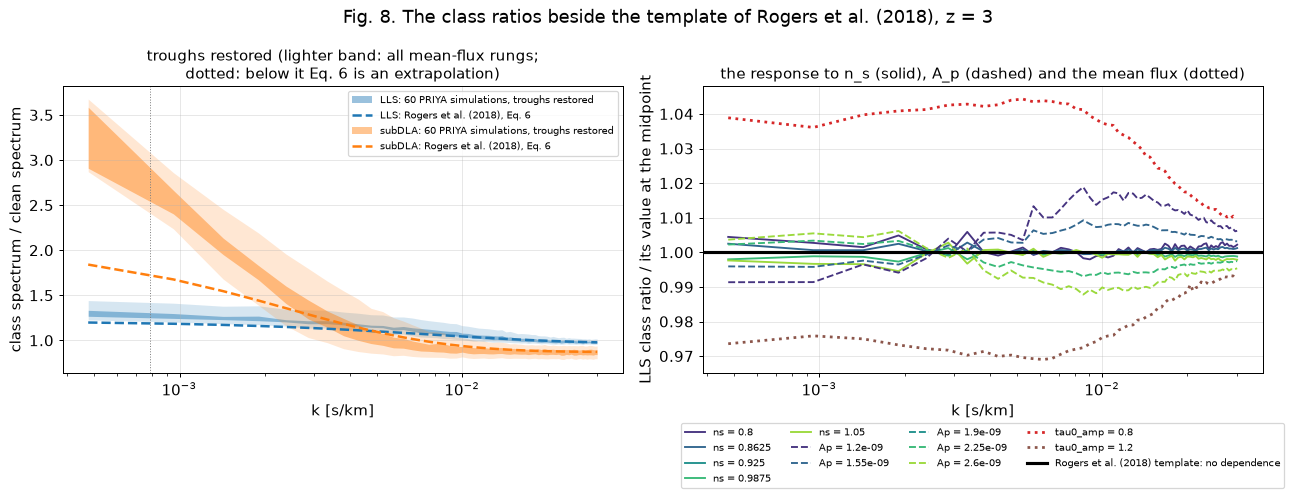

In [14]:
# Fig. 8. Left: the PRIYA training simulations with the filtered troughs restored, against Eq. 6 of Rogers et al.
# (2018), at z = 3 (the repository's comparison, redrawn for two classes). Right: the response of the emulator's
# LLS class ratio to n_s, A_p and the mean flux, which the template does not have; and a ranking over all inputs.
from hcd_analysis.hcd_template import class_ratio


def read_table(path):
    # a table with comment lines; the last comment line holds the column names
    with open(path, encoding="utf-8") as handle:
        names = [line for line in handle if line.startswith("#")][-1].lstrip("# ").strip().split(",")
    values = np.loadtxt(path, delimiter=",", comments="#")
    return {name: values[:, i] for i, name in enumerate(names)}


sims = read_table(tutorial_file(DATA + "class_ratio_ranges_z3p0_lf60.csv"))
k_sims = sims["k_s_per_km"]
eq6 = class_ratio(k_sims, 3.0)  # by class: "LLS", "Sub-DLA", "Small-DLA", "Large-DLA"

fig, axes = plt.subplots(1, 2, figsize=(15, 6.6))
ax = axes[0]
for stem, key in (("LLS", "LLS"), ("subDLA", "Sub-DLA")):
    wide = (sims[f"R_{stem}_sims60_allrungs_min"], sims[f"R_{stem}_sims60_allrungs_max"])
    narrow = (sims[f"R_{stem}_sims60_rung1_min"], sims[f"R_{stem}_sims60_rung1_max"])
    ax.fill_between(k_sims, *wide, color=CLASS_COLOURS[stem], alpha=0.18, lw=0)
    ax.fill_between(k_sims, *narrow, color=CLASS_COLOURS[stem], alpha=0.45, lw=0,
                    label=f"{stem}: 60 PRIYA simulations, troughs restored")
    ax.plot(k_sims, eq6[key], color=CLASS_COLOURS[stem], ls="--", lw=2, label=f"{stem}: Rogers et al. (2018), Eq. 6")
    inside_wide = (eq6[key] >= wide[0]) & (eq6[key] <= wide[1])
    inside_narrow = (eq6[key] >= narrow[0]) & (eq6[key] <= narrow[1])
    print(f"{stem:7s} Eq. 6 lies inside the range of the 60 simulations on {int(inside_narrow.sum())} of {k_sims.size} modes "
          f"at the mean-flux rung nearest 1, and on {int(inside_wide.sum())} at all mean-flux rungs")
ax.axvline(2.0 * np.pi / 8000.0, color="grey", lw=0.8, ls=":")
ax.set_xscale("log")
ax.set_xlabel("k [s/km]")
ax.set_ylabel("class spectrum / clean spectrum")
ax.set_title("troughs restored (lighter band: all mean-flux rungs;\ndotted: below it Eq. 6 is an extrapolation)")
ax.legend(fontsize=8)

ax = axes[1]
shown = pred.k < 0.03  # the box modes below 0.03 s/km at the midpoint
ratio_mid = pred.P_class[1] / pred.P_class[0]


def lls_ratio_relative(name, value):
    # the LLS class ratio with one input changed, over its value at the midpoint, box mode by box mode (hub and
    # omegamh2 move the wavenumber in s/km of a mode; the ratio is compared at the same mode)
    params = dict(PARAMS, **({name: value} if name in PARAMS else {}))
    other = emu.predict(params, z=3.0, tau0_amp=value if name == "tau0_amp" else 1.0, dtau0=0.0)
    return (other.P_class[1] / other.P_class[0]) / ratio_mid


INPUTS = list(zip(hp.PARAM_NAMES, hp.PARAM_LIMITS)) + [("tau0_amp", TAU0_AMP_RANGE)]
largest = {}
with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter("always")
    for name, (low, high) in INPUTS:
        largest[name] = max(
            float(np.max(np.abs(lls_ratio_relative(name, value)[shown] - 1.0))) for value in np.linspace(low, high, 5)
        )
    for name, style in (("ns", "-"), ("Ap", "--")):
        low, high = hp.PARAM_LIMITS[hp.PARAM_NAMES.index(name)]
        for value, shade in zip(np.linspace(low, high, 5), np.linspace(0.15, 0.85, 5)):
            ax.semilogx(pred.k[shown], lls_ratio_relative(name, value)[shown], style, color=plt.cm.viridis(shade),
                        label=f"{name} = {value:.4g}")
    for value, colour in ((0.8, "tab:red"), (1.2, "tab:brown")):
        ax.semilogx(pred.k[shown], lls_ratio_relative("tau0_amp", value)[shown], ":", lw=2.2, color=colour,
                    label=f"tau0_amp = {value:g}")
print("The largest change of the emulator's LLS class ratio below k = 0.03 s/km at z = 3 across the trained range of")
print("each input (five values; the others at the midpoint, tau0_amp = 1), largest first:")
for name in sorted(largest, key=lambda name: -largest[name]):
    print(f"  {name:11s} {100 * largest[name]:5.2f} per cent")
print("dtau0 is not varied: at one redshift it acts only through tau_eff, which tau0_amp already covers")
if caught:
    print(f"{len(caught)} of these predictions warned, the first: {str(caught[0].message)[:160]} ...")
ax.axhline(1.0, color="black", lw=2.5, label="Rogers et al. (2018) template: no dependence")
ax.set_xlabel("k [s/km]")
ax.set_ylabel("LLS class ratio / its value at the midpoint")
ax.set_title("the response to n_s (solid), A_p (dashed) and the mean flux (dotted)")
ax.legend(fontsize=8, ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.16))
fig.suptitle("Fig. 8. The class ratios beside the template of Rogers et al. (2018), z = 3")
fig.tight_layout(rect=(0, 0.1, 1, 1))
plt.show()

**PROVISIONAL (PI to refine).** The two panels of Fig. 8 answer different questions. On the left the filtered
troughs are restored, so levels can be compared with the template; the printed lines say on how many modes the
template lies inside the range of the simulations. On the right the emulator's class spectra are PRIYA-filtered,
so their level is not compared with the template: only the response to the inputs is shown, which a template
with no dependence on cosmology does not carry. The printed list ranks the inputs by the size of that response.

## Part III. Mock inference

**PROVISIONAL (PI to refine).** This part is a self-consistency demonstration on a mock made by the model
itself: not an independent validation, not a result from data.

### The Gaussian likelihood

For a data vector $d$ with covariance $C$ and a model vector $m(\theta)$,

$$\ln L(\theta) = -\tfrac{1}{2}\,[d - m(\theta)]^{T} C^{-1} [d - m(\theta)] - \tfrac{1}{2} \ln\det C - \tfrac{N}{2}\ln 2\pi .$$

The model vector is built in four steps: the prediction at $\theta$ at the redshifts of the data; the mixture of
the class spectra; linear interpolation in $k$ to the wavenumbers of the data; and the data set's own factor on the
model, when it has one. Three approximations are made, and `docs/likelihood.md` of the repository discusses each:
the covariance is that of the data alone, with no term for the error of the emulator; the model is interpolated
linearly to the data's bins; and the model is treated as exact.

### Relation to Ho et al. (2026)

**PROVISIONAL (PI to refine).** PLACEHOLDER: what the analysis of Ho et al. (2026) fitted, and with which
treatment of the HCD absorbers; each sentence is to be checked against the paper before it is written here.

What this notebook does instead: a mock, four free parameters, everything else fixed. It demonstrates the
machinery. It is not that analysis.

In [15]:
# The posterior of four parameters, assembled from public pieces of the package: like.prediction, hp.add_hcd and
# interp_to_bins. With all three amplitudes at 1 it is the public Gaussian likelihood.
import numpy as np
from scipy.linalg import solve_triangular

import hcd_analysis.predictor as hp
from hcd_analysis import likelihood as hl

# The point the mock is made at: the midpoint of the nine trained ranges, and PRIYA's mean flux at its centre.
TRUTH = {
    "ns": 0.925,
    "Ap": 1.9e-9,
    "herei": 4.0,
    "heref": 2.7,
    "alphaq": 2.15,
    "hub": 0.70,
    "omegamh2": 0.143,
    "hireionz": 7.25,
    "bhfeedback": 0.05,
    "tau0_amp": 1.0,
    "dtau0": 0.0,
}
# The amplitude of each HCD class in the mixture, relative to the model's own sightline fraction at the point.
REL_TRUTH = {"LLS": 1.0, "subDLA": 1.0, "DLA": 1.0}
# The four free parameters, in the order of the vector x of log_posterior. r_LLS is the LLS amplitude relative to
# the model's own fraction. Everything else stays at TRUTH and REL_TRUTH.
FREE = ("ns", "Ap", "tau0_amp", "r_LLS")
LIKE = None  # the likelihood object that holds the data; set by the notebook
PRIOR = None  # {name: (low, high)}, flat; set by the notebook from flat_prior
REFUSALS = {}  # {kind of refusal: [count, the first message]}, filled by log_posterior


def flat_prior(emu):
    # The flat prior of the four free parameters: ns and Ap on the ranges the model was trained on, tau0_amp on the
    # range of the mean-flux amplitude the model records with its training data, r_LLS from 0 to 3.
    limits = dict(zip(hp.PARAM_NAMES, hp.PARAM_LIMITS))
    low, high = emu.provenance["lineage"]["cache"]["settings"]["alpha_range"]
    return {
        "ns": (float(limits["ns"][0]), float(limits["ns"][1])),
        "Ap": (float(limits["Ap"][0]), float(limits["Ap"][1])),
        "tau0_amp": (float(low), float(high)),
        "r_LLS": (0.0, 3.0),
    }


def model_vector_free_hcd(like, theta, rel):
    # The model vector at theta (the eleven parameters by name) with the amplitude of each HCD class at rel[class]
    # times the model's own fraction: the four steps of the public likelihood, written out.
    data = like.data
    pred = like.prediction(theta)  # 1. the prediction at the redshifts of the data, on the model's own modes
    factors = np.array([rel[name] for name in hp.HCD_CLASSES], dtype=float)
    mixed = hp.add_hcd(pred, factors * pred.w_c)  # 2. P_clean + sum over classes of A_c (P_c - P_clean)
    if not np.all(np.isfinite(mixed)):
        raise hl.NonFiniteModelError("the model's spectrum is not finite at this point")
    out = np.empty(data.n)
    for i, (where, k_data) in enumerate(zip(data.slices(), data.k)):
        out[where] = hl.interp_to_bins(pred.k[i], mixed[i], k_data)  # 3. linear in k, never extrapolated
    if data.model_factor is not None:
        out = out * data.model_factor  # 4. the data set's own factor on the model
    return out


def chi_square_free_hcd(like, theta, rel):
    # r^T C^-1 r with r = model - data and C the symmetric part of the data covariance, through C = L L^T
    data = like.data
    lower = np.linalg.cholesky(0.5 * (data.cov + data.cov.T))
    white = solve_triangular(lower, model_vector_free_hcd(like, theta, rel) - data.p1d, lower=True)
    return float(white @ white)


def log_likelihood_free_hcd(like, theta, rel):
    # ln L = -1/2 chi-square - 1/2 ln det C - N/2 ln(2 pi)
    data = like.data
    lower = np.linalg.cholesky(0.5 * (data.cov + data.cov.T))
    log_det = 2.0 * float(np.sum(np.log(np.diag(lower))))
    white = solve_triangular(lower, model_vector_free_hcd(like, theta, rel) - data.p1d, lower=True)
    return -0.5 * float(white @ white) - 0.5 * log_det - 0.5 * data.n * np.log(2.0 * np.pi)


def log_posterior(x):
    # The log posterior at x = (ns, Ap, tau0_amp, r_LLS), up to a constant: the log likelihood inside the flat
    # prior, minus infinity outside it. Where the model cannot serve a point (the predictor refuses it, a data bin
    # falls outside the model's modes, or the spectrum is not finite) it is minus infinity too, and the refusal
    # is counted in REFUSALS, as the package's sampler_logp does.
    x = np.asarray(x, dtype=float)
    for value, name in zip(x, FREE):
        low, high = PRIOR[name]
        if not (low <= value <= high):  # a value that is not a number fails this too
            return -np.inf
    theta = dict(TRUTH, ns=float(x[0]), Ap=float(x[1]), tau0_amp=float(x[2]))
    rel = dict(REL_TRUTH, LLS=float(x[3]))
    try:
        return log_likelihood_free_hcd(LIKE, theta, rel)
    except (hp.MFUnavailableError, hp.MFRangeError):
        raise  # wrong for every point, never a refusal of one point
    except (hp.PredictorInputError, hl.OutsideModesError, hl.NonFiniteModelError) as error:
        entry = REFUSALS.setdefault(type(error).__name__, [0, str(error)])
        entry[0] += 1
        return -np.inf

In [16]:
# The mock. Its bins, its covariance and its factor on the model are those of the public example data set of the
# release; its data vector is made here by the published model at TRUTH, with the model's own class fractions.
import dataclasses
import tarfile

EXAMPLE_MOCK_SHA256 = "b7db66e81a20c25de571f39fad1a362d7c844a855487a46b31208354ce5efc34"  # of mock.p1d.json


def example_member(name, sha256):
    # one file of the example download, taken out of its archive into the cache folder and checked by sha256
    target = tutorial_cache() / "hcd_priya_example_download" / name
    if not (target.is_file() and sha256_of(target) == sha256):
        with tarfile.open(tutorial_file("hcd_priya_example_download.tar.gz")) as archive:
            content = archive.extractfile("hcd_priya_example_download/" + name).read()
        if hashlib.sha256(content).hexdigest() != sha256:
            raise RuntimeError(f"{name} in the example download does not have the sha256 {sha256}")
        target.parent.mkdir(parents=True, exist_ok=True)
        handle, partial = tempfile.mkstemp(dir=target.parent, prefix=name + ".", suffix=".part")
        with os.fdopen(handle, "wb") as out:
            out.write(content)
        os.replace(partial, target)
    return target


example = hl.read_p1d_data(example_member("mock.p1d.json", EXAMPLE_MOCK_SHA256), expected_sha256=EXAMPLE_MOCK_SHA256)
print(f"the example data set: {example.n} bins at {len(example.z)} redshifts")
for z, k_row in zip(example.z, example.k):
    print(f"  z = {z:.1f}: {k_row.size} bins, k from {k_row[0]:.2e} to {k_row[-1]:.2e} s/km")
print("its factor on the model vector:", "none" if example.model_factor is None
      else f"from {example.model_factor.min():.4f} to {example.model_factor.max():.4f}")

mock_vector = hl.GaussianP1DLikelihood(emu, example).model_vector(TRUTH)
MOCK = dataclasses.replace(
    example,
    p1d=mock_vector,
    truth=dict(TRUTH, r_LLS=REL_TRUTH["LLS"]),
    provenance={
        "what": "a mock made by the published model itself at a stated point; no noise is added",
        "model_release_sha256": emu.provenance["release"]["release_sha256"],
        "bins_covariance_and_factor_from": "mock.p1d.json of the example download, sha256 " + EXAMPLE_MOCK_SHA256,
    },
)
LIKE = hl.GaussianP1DLikelihood(emu, MOCK)

at_truth = LIKE.prediction(TRUTH)
print()
print("the truth of the mock:", ", ".join(f"{name} = {value:g}" for name, value in TRUTH.items()))
print("class amplitudes: the model's own fractions (relative amplitudes", REL_TRUTH, ")")
print("flags of the prediction at the truth:", sorted(name for name, value in at_truth.flags.items() if np.any(value == True)))  # noqa: E712
chi2_truth = LIKE.chi2(TRUTH)
assert chi2_truth == 0.0, chi2_truth
print("chi-square at the truth:", chi2_truth, "(the data vector is the model vector there)")

the example data set: 121 bins at 11 redshifts
  z = 4.2: 11 bins, k from 5.50e-03 to 6.27e-02 s/km
  z = 4.0: 11 bins, k from 5.50e-03 to 6.27e-02 s/km
  z = 3.8: 11 bins, k from 5.50e-03 to 6.27e-02 s/km
  z = 3.6: 11 bins, k from 5.50e-03 to 6.27e-02 s/km
  z = 3.4: 11 bins, k from 5.50e-03 to 6.27e-02 s/km
  z = 3.2: 11 bins, k from 5.50e-03 to 6.27e-02 s/km
  z = 3.0: 11 bins, k from 5.50e-03 to 6.27e-02 s/km
  z = 2.8: 11 bins, k from 5.50e-03 to 6.27e-02 s/km
  z = 2.6: 11 bins, k from 5.50e-03 to 6.27e-02 s/km
  z = 2.4: 11 bins, k from 5.50e-03 to 6.27e-02 s/km
  z = 2.2: 11 bins, k from 5.50e-03 to 6.27e-02 s/km
its factor on the model vector: from 0.9538 to 1.0228



the truth of the mock: ns = 0.925, Ap = 1.9e-09, herei = 4, heref = 2.7, alphaq = 2.15, hub = 0.7, omegamh2 = 0.143, hireionz = 7.25, bhfeedback = 0.05, tau0_amp = 1, dtau0 = 0
class amplitudes: the model's own fractions (relative amplitudes {'LLS': 1.0, 'subDLA': 1.0, 'DLA': 1.0} )
flags of the prediction at the truth: ['cddf_bins_without_support', 'incidence_heldout_error_available', 'incidence_mf_applied', 'k_downweighted', 'mf_applied', 'p1d_validation_available']
chi-square at the truth: 0.0 (the data vector is the model vector there)


> **What this mock is. PROVISIONAL (PI to refine).**
>
> - The data vector is made by the same published model that is fitted to it, at the stated point. The truth of
>   every parameter is known by construction.
> - No noise is added to the data vector. The covariance is that of the public example data set.
> - It tests the machinery and shows degeneracies. It is a self-consistency demonstration: **not an independent
>   validation of the model, and not a result from data.**

In [17]:
# The four free parameters and their prior. The other seven PRIYA parameters, dtau0 and the subDLA and DLA
# amplitudes are fixed at the truth.
PRIOR = flat_prior(emu)
print("the prior of the four free parameters: uniform within the stated ranges, restricted to physically allowed")
print("class fractions. The stated ranges:")
for name in FREE:
    truth = REL_TRUTH["LLS"] if name == "r_LLS" else TRUTH[name]
    print(f"  {name:9s} from {PRIOR[name][0]:.6g} to {PRIOR[name][1]:.6g}   (truth {truth:g})")
print("  ns and Ap: the ranges the model was trained on (hp.PARAM_LIMITS); tau0_amp: the range of the mean-flux")
print("  amplitude recorded with the model's training data (emu.provenance); r_LLS: the LLS amplitude relative")
print("  to the model's own fraction, from 0 to 3")
print("The restriction: the class fractions (r_LLS times the model's own LLS fraction, plus its subDLA and DLA")
print("  fractions) sum to at most one at every redshift of the data. A point where they do not is refused by the")
print("  model: log_posterior returns minus infinity there and counts it in REFUSALS.")
w_truth = np.asarray(LIKE.prediction(TRUTH).w_c)  # one row per redshift of the data: LLS, subDLA, DLA
i_lls, i_sub, i_dla = (hp.HCD_CLASSES.index(name) for name in ("LLS", "subDLA", "DLA"))
r_one = (1.0 - w_truth[:, i_sub] - w_truth[:, i_dla]) / w_truth[:, i_lls]
print(f"  At the truth the fractions sum to one at r_LLS = {r_one.min():.3f} (at z = {MOCK.z[int(np.argmin(r_one))]:.1f}), "
      f"inside the stated range: there the restriction, not the range, is the upper end of r_LLS.")
print("fixed at the truth:", ", ".join(name for name in TRUTH if name not in FREE), "and the subDLA and DLA amplitudes")

X_TRUTH = np.array([TRUTH["ns"], TRUTH["Ap"], TRUTH["tau0_amp"], REL_TRUTH["LLS"]])
print()
print(f"log posterior at the truth: {log_posterior(X_TRUTH):.6f}   the public likelihood there: {LIKE.loglike(TRUTH):.6f}")

# The assembly above against the public likelihood at fixed HCD amplitudes: four LLS amplitudes, three points.
POINTS = (TRUTH, dict(TRUTH, ns=0.87, Ap=2.3e-9), dict(TRUTH, tau0_amp=1.12, ns=0.96))
worst_vector = worst_loglike = 0.0
for r_lls in (0.0, 0.5, 1.0, 2.0):
    rel = dict(REL_TRUTH, LLS=r_lls)
    public = hl.GaussianP1DLikelihood(emu, MOCK, hcd_relative_to_priya=rel)
    for theta in POINTS:
        ours, theirs = model_vector_free_hcd(LIKE, theta, rel), public.model_vector(theta)
        worst_vector = max(worst_vector, float(np.max(np.abs(ours / theirs - 1.0))))
        worst_loglike = max(worst_loglike, abs(log_likelihood_free_hcd(LIKE, theta, rel) / public.loglike(theta) - 1.0))
print(f"against the public likelihood at 12 points: largest relative difference of the model vector {worst_vector:.1e}, "
      f"of the log likelihood {worst_loglike:.1e}")
assert worst_vector < 1e-12 and worst_loglike < 1e-10

the prior of the four free parameters: uniform within the stated ranges, restricted to physically allowed
class fractions. The stated ranges:
  ns        from 0.8 to 1.05   (truth 0.925)
  Ap        from 1.2e-09 to 2.6e-09   (truth 1.9e-09)
  tau0_amp  from 0.655556 to 1.33125   (truth 1)
  r_LLS     from 0 to 3   (truth 1)
  ns and Ap: the ranges the model was trained on (hp.PARAM_LIMITS); tau0_amp: the range of the mean-flux
  amplitude recorded with the model's training data (emu.provenance); r_LLS: the LLS amplitude relative
  to the model's own fraction, from 0 to 3
The restriction: the class fractions (r_LLS times the model's own LLS fraction, plus its subDLA and DLA
  fractions) sum to at most one at every redshift of the data. A point where they do not is refused by the
  model: log_posterior returns minus infinity there and counts it in REFUSALS.
  At the truth the fractions sum to one at r_LLS = 2.291 (at z = 4.2), inside the stated range: there the restriction, not the range

against the public likelihood at 12 points: largest relative difference of the model vector 0.0e+00, of the log likelihood 0.0e+00


In [18]:
import numpy as np


def metropolis(logp, x0, cov, n_steps, rng):
    # A random-walk Metropolis sampler. Each step proposes x + a normal draw with covariance cov (fixed for the whole
    # run) and accepts it with probability min(1, exp(logp(proposal) - logp(x))); a proposal where logp is minus
    # infinity, or not a number, is never accepted. Returns the chain, shape (n_steps, d), the log posterior of each
    # state, and the fraction of steps that moved.
    x = np.array(x0, dtype=float)
    step = np.linalg.cholesky(np.asarray(cov, dtype=float))
    current = float(logp(x))
    if not np.isfinite(current):
        raise ValueError("the chain must start where the log posterior is finite")
    chain = np.empty((n_steps, x.size))
    logps = np.empty(n_steps)
    accepted = 0
    for i in range(n_steps):
        proposal = x + step @ rng.standard_normal(x.size)
        value = float(logp(proposal))
        if np.log(rng.uniform()) < value - current:  # false when value is minus infinity or not a number
            x, current = proposal, value
            accepted += 1
        chain[i] = x
        logps[i] = current
    return chain, logps, accepted / n_steps

In [19]:
# Convergence diagnostics after Vehtari, Gelman, Simpson, Carpenter and Buerkner (2021): the rank-normalised split
# R-hat and the bulk and tail effective sample sizes.
import numpy as np
from scipy.special import ndtri
from scipy.stats import rankdata


def rank_normalise(x):
    # the draws of all chains ranked together, and the ranks turned into normal scores
    ranks = rankdata(x, method="average").reshape(x.shape)
    return ndtri((ranks - 0.375) / (x.size + 0.25))


def rhat_of(x):
    # the potential scale reduction of the chains x, shape (chains, draws): sqrt(pooled variance / within variance)
    n = x.shape[1]
    within = x.var(axis=1, ddof=1).mean()
    between = n * x.mean(axis=1).var(ddof=1)
    return float(np.sqrt(((n - 1.0) / n * within + between / n) / within))


def ess_of(x):
    # the effective sample size of the chains x, shape (chains, draws): the number of draws over the integrated
    # autocorrelation time, with the autocorrelations combined over the chains and summed in pairs while the pairs
    # stay positive and do not increase (Geyer's initial monotone sequence)
    m, n = x.shape
    centred = x - x.mean(axis=1, keepdims=True)
    size = 1 << int(np.ceil(np.log2(2 * n)))
    spectrum = np.fft.rfft(centred, n=size, axis=1)
    acov = np.fft.irfft(spectrum * np.conj(spectrum), n=size, axis=1)[:, :n] / n
    mean_var = acov[:, 0].mean() * n / (n - 1.0)
    var_plus = mean_var * (n - 1.0) / n
    if m > 1:
        var_plus += x.mean(axis=1).var(ddof=1)
    if not var_plus > 0.0:
        return float("nan")
    rho = np.zeros(n)
    rho_even, rho_odd = 1.0, 1.0 - (mean_var - acov[:, 1].mean()) / var_plus
    rho[0], rho[1] = rho_even, rho_odd
    t = 1
    while t < n - 3 and rho_even + rho_odd > 0.0:
        rho_even = 1.0 - (mean_var - acov[:, t + 1].mean()) / var_plus
        rho_odd = 1.0 - (mean_var - acov[:, t + 2].mean()) / var_plus
        if rho_even + rho_odd >= 0.0:
            rho[t + 1], rho[t + 2] = rho_even, rho_odd
        t += 2
    last = t - 2
    if rho_even > 0.0:
        rho[last + 1] = rho_even
    t = 1
    while t <= last - 2:
        if rho[t + 1] + rho[t + 2] > rho[t - 1] + rho[t]:
            rho[t + 1] = (rho[t - 1] + rho[t]) / 2.0
            rho[t + 2] = rho[t + 1]
        t += 2
    total = m * n
    tau = -1.0 + 2.0 * rho[: last + 1].sum() + rho[last + 1 : last + 2].sum()
    return float(total / max(tau, 1.0 / np.log10(total)))


def split_rhat_and_ess(chains):
    # For chains of shape (chains, steps, parameters), per parameter:
    #   rhat      the rank-normalised split R-hat: each chain is cut in two halves; the larger of the R-hat of the
    #             normal scores of the draws and of their absolute distances from the median (which sees chains
    #             that agree in location and differ in width);
    #   ess_bulk  the effective sample size of the normal scores, over the split chains;
    #   ess_tail  the smaller of the effective sample sizes of the indicators "the draw lies below the 5 per cent
    #             quantile" and "below the 95 per cent quantile".
    chains = np.asarray(chains, dtype=float)
    if chains.ndim != 3:
        raise ValueError("chains must have the shape (chains, steps, parameters)")
    half = chains.shape[1] // 2
    split = np.concatenate([chains[:, :half], chains[:, half : 2 * half]], axis=0)
    out = {"rhat": [], "ess_bulk": [], "ess_tail": []}
    for j in range(chains.shape[2]):
        x = split[:, :, j]
        bulk = rank_normalise(x)
        folded = rank_normalise(np.abs(x - np.median(x)))
        out["rhat"].append(max(rhat_of(bulk), rhat_of(folded)))
        out["ess_bulk"].append(ess_of(bulk))
        low, high = np.quantile(x, [0.05, 0.95])
        out["ess_tail"].append(min(ess_of((x <= low).astype(float)), ess_of((x <= high).astype(float))))
    return {name: np.array(values) for name, values in out.items()}

In [20]:
# Chains as text files in the layout that Cobaya writes and GetDist reads: PREFIX.1.txt, PREFIX.2.txt, ... with the
# columns "weight minuslogpost" and one column per parameter, PREFIX.paramnames and PREFIX.ranges. A state the
# chain stays in for several steps is one row, with the number of steps as its weight.
import pathlib

import numpy as np


def write_chains(prefix, chains, logps, names, ranges):
    # chains: (chains, steps, parameters); logps: (chains, steps); names: the parameter names; ranges: {name: (low,
    # high)}. Existing files are never overwritten.
    prefix = pathlib.Path(prefix)
    chains, logps = np.asarray(chains, dtype=float), np.asarray(logps, dtype=float)
    with open(f"{prefix}.paramnames", "x", encoding="utf-8") as out:
        out.write("".join(f"{name}\n" for name in names))
    with open(f"{prefix}.ranges", "x", encoding="utf-8") as out:
        out.write("".join(f"{name} {float(ranges[name][0])!r} {float(ranges[name][1])!r}\n" for name in names))
    n_steps = chains.shape[1]
    for c in range(chains.shape[0]):
        with open(f"{prefix}.{c + 1}.txt", "x", encoding="utf-8") as out:
            out.write("# weight minuslogpost " + " ".join(names) + "\n")
            start = 0
            for t in range(1, n_steps + 1):
                if t == n_steps or np.any(chains[c, t] != chains[c, start]):
                    values = " ".join(f"{value:.12e}" for value in chains[c, start])
                    out.write(f"{t - start:d} {-logps[c, start]:.12e} {values}\n")
                    start = t


def read_chains(prefix):
    # the rows of PREFIX.1.txt, PREFIX.2.txt, ... in order: the samples (rows, parameters), the weight of each row
    # and the number of the chain it belongs to (from 1)
    prefix = pathlib.Path(prefix)
    samples, weights, index = [], [], []
    number = 1
    while pathlib.Path(f"{prefix}.{number}.txt").is_file():
        table = np.loadtxt(f"{prefix}.{number}.txt", ndmin=2)
        samples.append(table[:, 2:])
        weights.append(np.rint(table[:, 0]).astype(int))
        index.append(np.full(table.shape[0], number))
        number += 1
    if not samples:
        raise FileNotFoundError(f"no chain file {prefix}.1.txt")
    return np.concatenate(samples), np.concatenate(weights), np.concatenate(index)


def expand_chains(samples, weights, index):
    # the chains step by step again, shape (chains, steps, parameters): each row repeated by its weight
    chains = [np.repeat(samples[index == number], weights[index == number], axis=0) for number in np.unique(index)]
    if len({chain.shape[0] for chain in chains}) != 1:
        raise ValueError("the chains do not have the same number of steps")
    return np.stack(chains)

In [21]:
import numpy as np


def levels_68_95(h2d):
    # the two heights of a two-dimensional histogram above which 68 and 95 per cent of its total lie
    values = np.sort(np.asarray(h2d, dtype=float).ravel())[::-1]
    cumulative = np.cumsum(values) / values.sum()
    return tuple(float(values[np.searchsorted(cumulative, fraction)]) for fraction in (0.68, 0.95))

### Sampling

**PROVISIONAL (PI to refine).** The cells above define a random-walk Metropolis sampler (`metropolis`), the
convergence diagnostics (`split_rhat_and_ess`: the rank-normalised split R-hat and the bulk and tail effective
sample sizes, after Vehtari et al. 2021), and the reading and writing of chains as text files in the layout that
Cobaya writes and GetDist reads. The next cell runs the sampler for 300 steps, to show that it runs.

In [22]:
# A short chain, run here: 300 steps from the truth. INSTRUCTIONAL ONLY, NOT EVIDENCE OF CONVERGENCE: it shows that
# the sampler runs and what it returns. Nothing is concluded from it.
LIVE_STEPS = 300
live_widths = np.array([0.02 * (PRIOR[name][1] - PRIOR[name][0]) for name in FREE])  # 2 per cent of each range
REFUSALS.clear()
live_chain, live_logp, live_acceptance = metropolis(
    log_posterior, X_TRUTH, np.diag(live_widths**2), LIVE_STEPS, np.random.default_rng(20261121)
)
print(f"{LIVE_STEPS} steps (instructional only, not evidence of convergence); acceptance {live_acceptance:.2f}")
print(f"{'parameter':10s} {'truth':>11s} {'smallest':>11s} {'largest':>11s}   visited in these steps")
for j, name in enumerate(FREE):
    print(f"{name:10s} {X_TRUTH[j]:11.4g} {live_chain[:, j].min():11.4g} {live_chain[:, j].max():11.4g}")
print("points refused by the model (class fractions above one, counted by log_posterior):",
      {kind: entry[0] for kind, entry in REFUSALS.items()} or "none")
live = split_rhat_and_ess(live_chain[None, :, :])
print("the diagnostics run on it, one chain cut in two halves (they are far from any threshold, as they must be after 300 steps):")
print("  split R-hat:", ", ".join(f"{name} {value:.2f}" for name, value in zip(FREE, live["rhat"])))
print("  bulk ESS:   ", ", ".join(f"{name} {value:.0f}" for name, value in zip(FREE, live["ess_bulk"])))
print("  tail ESS:   ", ", ".join(f"{name} {value:.0f}" for name, value in zip(FREE, live["ess_tail"])))

300 steps (instructional only, not evidence of convergence); acceptance 0.48
parameter        truth    smallest     largest   visited in these steps
ns               0.925      0.8871      0.9614
Ap             1.9e-09   1.709e-09   2.195e-09
tau0_amp             1      0.9772       1.025
r_LLS                1      0.5504       1.172
points refused by the model (class fractions above one, counted by log_posterior): none
the diagnostics run on it, one chain cut in two halves (they are far from any threshold, as they must be after 300 steps):
  split R-hat: ns 1.55, Ap 1.55, tau0_amp 1.27, r_LLS 1.18
  bulk ESS:    ns 2, Ap 6, tau0_amp 4, r_LLS 4
  tail ESS:    ns 18, Ap 24, tau0_amp 30, r_LLS 27


### The stored chains

**PENDING: the stored chains have not been run. They are run once, after the project lead's approval of the
preflight; this cell is filled then.**

It will read four independently started chains from text files in this repository, each checked by its sha256,
with a provenance file that states the code, the model, the mock, the truth, the prior, the seeds and the
diagnostics. The code that makes them is `run_mock_chain.py` beside this notebook; it runs the cells of this
notebook.

### Convergence of the stored chains

**PENDING: the stored chains have not been run. They are run once, after the project lead's approval of the
preflight; this cell is filled then.**

It will print, for each of the four parameters, the rank-normalised split R-hat and the bulk and the tail
effective sample size of the stored chains, recomputed from the files, the acceptance of each chain, and two
further diagnostics of their own: the share of proposals refused because the class fractions would sum to more
than one, and the share of samples at the edge of the multi-fidelity tables in the mean flux. No contour is
shown unless every convergence criterion is met.

### The posterior of the four parameters

**PENDING: the stored chains have not been run. They are run once, after the project lead's approval of the
preflight; this cell is filled then.**

**Fig. 9** will show the 68 and 95 per cent contours of each pair of the four parameters and their marginals,
with the truth marked, and print the correlations. The contours are conditional on the fixed parameters; the
mock is made by the model itself. They are not marginalised constraints.

### The prediction of the posterior, and the posterior predictive

**PENDING: the stored chains have not been run. They are run once, after the project lead's approval of the
preflight; this cell is filled then.**

**Fig. 10** will show two bands at each redshift, drawn apart: the posterior uncertainty of the model
prediction (the range of the model vector over draws of the posterior), and the posterior predictive of the
data (the same with a draw of the data covariance added). It is a self-consistency demonstration on a mock made
by the model itself: not an independent validation, not a result from data.

## Limits, and where to go next

**PROVISIONAL (PI to refine).**

- Part III fits a mock made by the same model. It shows how the pieces fit together and which parameters trade
  off. It does not validate the model, and it is not a constraint from data.
- The likelihood uses the covariance of the data alone. The held-out prediction residual of Part II is an
  empirical validation diagnostic, not a calibrated predictive uncertainty, and it does not enter the likelihood.
- The class spectra are PRIYA-filtered, and the mixture leaves out what the filter removed.

Where to go next, in the repository: `docs/likelihood.md` (the likelihood, its options and what it refuses);
`examples/mock_recovery.py` (a mock from a simulation, fitted with a model made without that simulation);
`docs/model_figures.md` (the model against published measurements); `docs/p1d_definition.md` (the conventions).